# Boston Bus Equity: October Project Check-In

**Students:** Caleb Lee, Emir Kavukcu, Travis Meyer, Toriana Mullins, Ziad Alharbi
**Project:** Boston Bus Equity (Spark! / CS506)
**Check-in date:** ____________

This notebook is written against the October check-in rubric, and it runs from raw download to final figures.

| Rubric item | Points | Where |
|---|---|---|
| At least one relevant visualization | 5 | Section 5 (Figures 1-10) |
| Clear, readable, well-labeled visualizations | 5 | Section 5, plus a "Defending this chart" note under each figure |
| Visualizations support or challenge a project claim | 5 | "Verdict" line under each figure; summary in Section 6 |
| Data sources and collection methods identified | 5 | Section 2 |
| Cleaning steps close to final | 5 | Section 3, with row-level audit tables |
| Reasoning for processing decisions explained | 5 | "Why" notes in Section 3; limitations in Section 7 |

## Main findings

- **Ridership:** weekday bus boardings were 79% of the Fall 2019 level in Fall 2024 and 80% in Fall 2025, and the change varies widely by route.
- **Reliability:** routes passed the MBTA's on-time test at 66.3% of timepoints in 2024, down about 4 points from early 2020 on a like-for-like basis. Route rates range from 40% to 80%.
- **Riders' time:** riders on frequent routes wait about 8.6 minutes, 1.7 minutes more than the schedule implies. We estimate about 27,600 rider-hours lost each weekday.
- **Target routes:** the Livable Streets routes do not differ from other routes on the on-time test, but they run later on average, by 1.4 minutes.
- **Equity:** neighborhood race and income show no link to the on-time test, but they show a modest link to lateness. The most-minority quarter of routes averages 4.9 minutes of delay, against 3.9 for the least-minority quarter. The two measures disagree mainly because routes in minority neighborhoods are more often judged by the frequent-service test, which measures gaps between buses and not lateness against the timetable.

## 1. Questions and hypotheses

The goal, from our README, is to measure how MBTA bus performance varies across the Boston area and to identify the residents most affected by gaps in service. Each hypothesis below is one the data could prove wrong.

| # | Claim we test | Project question | Figures |
|---|---|---|---|
| H1 | Bus ridership has not fully returned to pre-pandemic levels, and the recovery differs by route | Ridership per route, pre vs post pandemic | 1, 2 |
| H2 | Actual trips take longer and are less predictable than scheduled | End-to-end travel time and variation | 3 |
| H3 | Riders wait longer than the schedule promises, especially when buses run late | Average wait, on time vs delayed | 4 |
| H4 | Reliability differs substantially between routes | Service-level disparities | 5 |
| H5 | The 15 Livable Streets target routes perform worse than other routes | Average delay of target routes; changes over time | 5, 6 |
| H6 | Worse service falls disproportionately on minority and low-income riders and neighborhoods | Who is most impacted | 7, 8, 9 |
| H7 | Lost time is concentrated on a small number of routes | Impact on riders (hours lost) | 10 |

## 2. Data sources and collection

All data is collected by the code below and cached in `data/raw/`. Re-running skips files that already exist. The notebook needs only `numpy`, `scipy`, `matplotlib`, and `openpyxl`, and runs locally or on Colab. It does not use `pandas` or `geopandas`, because their compiled libraries were blocked by Windows Application Control on the machine used to build it.

| Dataset | Publisher | How we collect it | Coverage used | Used for |
|---|---|---|---|---|
| Bus Arrival Departure Times 2024 | MBTA (ArcGIS Hub, item `96c77138…`) | Direct ZIP download | Jan-Nov 2024, weekdays | Reliability, delay, wait, travel time |
| Bus Arrival Departure Times 2020 | MBTA (ArcGIS Hub, item `4c129315…`) | Direct ZIP download | Jan-Feb 2020, weekdays | Pre-pandemic baseline |
| Bus Ridership by Trip, Season, Route, Line and Stop | MBTA (ArcGIS Hub, item `8daf4a33…`) | Direct ZIP download | Fall 2016 to Fall 2025, weekdays | Ridership, rider weights |
| 2025 System-Wide Passenger Survey | MBTA (ArcGIS Feature Service) | Paged REST query | Bus reporting groups | Rider demographics by route |
| 2015-17 Passenger Survey, results by line | CTPS | Direct XLSX download | Bus routes | Demographic change over time |
| GTFS `stops.txt` | MBTA | Direct ZIP download | Current feed | Stop latitude and longitude |
| ACS 2020-2024 5-year, tables B19013 and B03002 | US Census, through Census Reporter API | REST query by county | 5 counties, tract level | Neighborhood income and race |
| 2020 Census tract boundaries | US Census TIGERweb | Paged REST query (GeoJSON) | Same 5 counties | Joining stops to tracts |
| Service Delivery Policy (Fall 2024) | MBTA | Read by hand | Table 6 | Definition of "on time" |

In [1]:
import array, csv, io, json, math, re, shutil, subprocess, time, urllib.parse, urllib.request, zipfile
from collections import defaultdict, Counter
from datetime import date
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.path import Path as MplPath
from scipy import stats
import openpyxl
from IPython.display import HTML, display

ROOT = Path.cwd()
RAW, OUT, FIGS = ROOT / "data/raw", ROOT / "data/processed", ROOT / "figures"
for p in (RAW, OUT, FIGS):
    p.mkdir(parents=True, exist_ok=True)

ITEM = "https://www.arcgis.com/sharing/rest/content/items/{}/data"
SOURCES = {
    "MBTA_Bus_Arrival_Departure_Times_2024.zip": ITEM.format("96c77138c3144906bce93d0257531b6a"),
    "MBTA_Bus_Arrival_Departure_Times_2020.zip": ITEM.format("4c1293151c6c4a069d49e6b85ee68ea4"),
    "MBTA_Bus_Ridership.zip": ITEM.format("8daf4a33925a4df59183f860826d29ee"),
    "CTPS_2015_17_survey_by_station_and_line.xlsx":
        "https://www.ctps.org/dv/mbtasurvey2018/MBTA%20systemwide%20survey%20results%20by%20station%20and%20line.xlsx",
    "MBTA_GTFS.zip": "https://cdn.mbta.com/MBTA_GTFS.zip",
}
SURVEY_URL = ("https://services1.arcgis.com/ceiitspzDAHrdGO1/arcgis/rest/services/"
              "MBTA_2025_System-Wide_Passenger_Survey/FeatureServer/0/query")
TIGER_URL = "https://tigerweb.geo.census.gov/arcgis/rest/services/TIGERweb/Tracts_Blocks/MapServer/10/query"
ACS_URL = "https://api.censusreporter.org/1.0/data/show/latest"
COUNTIES = {"025": "Suffolk", "017": "Middlesex", "021": "Norfolk", "009": "Essex", "023": "Plymouth"}

# The 15 target routes named in the project brief (Livable Streets), with the
# 2018 average weekday ridership printed in that report, used below as a validation check.
TARGET = ["22", "29", "15", "45", "28", "44", "42", "17", "23", "31", "26", "111", "24", "33", "14"]
LSA_2018 = {"22": 8015, "29": 2254, "15": 5808, "45": 3142, "28": 12880, "44": 3453, "42": 2564, "17": 3091,
            "23": 11808, "31": 6096, "26": 1585, "111": 12037, "24": 1672, "33": 1356, "14": 1293}
NAMES = {"741": "SL1", "742": "SL2", "743": "SL3", "746": "SLW", "749": "SL5", "751": "SL4",
         "701": "CT1", "747": "CT2", "708": "CT3"}
label = lambda r: NAMES.get(r, r)

def fetch_json(url, params=None, tries=3):
    if params:
        url += "?" + urllib.parse.urlencode(params, safe="|")
    for i in range(tries):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "cs506-boston-bus-equity"})
            with urllib.request.urlopen(req, timeout=180) as r:
                return json.load(r)
        except Exception:
            if i == tries - 1:
                raise
            time.sleep(3 * (i + 1))

def write_csv(path, rows, cols):
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(cols)
        w.writerows([r[c] for c in cols] for r in rows)

def read_csv(path):
    # Numeric-looking values become floats; route and stop ids stay strings.
    keep = {"route", "stop_id", "month", "season", "group", "geoid", "status", "direction", "point_type", "standard", "reporting_group", "category"}
    with open(path, newline="", encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    for r in rows:
        for k, v in r.items():
            if k not in keep:
                try:
                    r[k] = float(v)
                except (TypeError, ValueError):
                    pass
    return rows

def show(rows, cols=None, fmt=None, n=None):
    # A small table renderer: every figure has a table twin so no value depends on reading a chart.
    cols = cols or list(rows[0]); fmt = fmt or {}
    rows = rows[:n] if n else rows
    cell = lambda r, c: fmt[c].format(r[c]) if c in fmt and isinstance(r[c], (int, float)) else r[c]
    head = "".join(f"<th>{c}</th>" for c in cols)
    body = "".join("<tr>" + "".join(f"<td>{cell(r, c)}</td>" for c in cols) + "</tr>" for r in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

for name, url in SOURCES.items():
    if not (RAW / name).exists():
        print("downloading", name)
        urllib.request.urlretrieve(url, RAW / name)

# The 2020 archive uses Deflate64, which Python's zipfile cannot read, so we call the unzip tool
# (preinstalled on Colab and Linux; on Windows it ships with Git for Windows).
Q1_2020 = RAW / "Bus Arrival Departure Times Jan-Mar 2020.csv"
if not Q1_2020.exists():
    unzip = shutil.which("unzip") or r"C:\Program Files\Git\usr\bin\unzip.exe"
    subprocess.run([unzip, "-o", "-j", str(RAW / "MBTA_Bus_Arrival_Departure_Times_2020.zip"), Q1_2020.name, "-d", str(RAW)], check=True)

survey_path = RAW / "MBTA_2025_survey.csv"
if not survey_path.exists():
    rows, offset = [], 0
    while True:
        page = fetch_json(SURVEY_URL, {"where": "1=1", "outFields": "*", "returnGeometry": "false", "f": "json",
                                       "resultOffset": offset, "resultRecordCount": 2000, "orderByFields": "ObjectId"})
        rows += [x["attributes"] for x in page["features"]]
        offset += len(page["features"])
        if not page["features"] or not page.get("exceededTransferLimit"):
            break
    write_csv(survey_path, rows, list(rows[0]))

tract_path, acs_path = RAW / "tracts_2020.geojson", RAW / "acs_tracts.json"
if not tract_path.exists():
    feats = []
    for c in COUNTIES:
        offset = 0
        while True:
            page = fetch_json(TIGER_URL, {"where": f"STATE='25' AND COUNTY='{c}'", "outFields": "GEOID", "outSR": 4326,
                                          "geometryPrecision": 5, "f": "geojson", "resultOffset": offset, "resultRecordCount": 500})
            feats += page["features"]
            offset += len(page["features"])
            if len(page["features"]) < 500:
                break
    tract_path.write_text(json.dumps({"type": "FeatureCollection", "features": feats}))
if not acs_path.exists():
    acs = {}
    for c in COUNTIES:
        d = fetch_json(ACS_URL, {"table_ids": "B19013,B03002", "geo_ids": f"140|05000US25{c}"})
        release = d["release"]
        for g, v in d["data"].items():
            acs[g.replace("14000US", "")] = {"income": v["B19013"]["estimate"]["B19013001"],
                                             "pop": v["B03002"]["estimate"]["B03002001"],
                                             "nh_white": v["B03002"]["estimate"]["B03002003"]}
    acs_path.write_text(json.dumps({"release": release, "tracts": acs}))

show([{"file": p.name, "size_MB": p.stat().st_size / 1e6} for p in sorted(RAW.iterdir())], fmt={"size_MB": "{:,.1f}"})

file,size_MB
acs_tracts.json,0.1
Bus Arrival Departure Times Jan-Mar 2020.csv,891.0
CTPS_2015_17_survey_by_station_and_line.xlsx,0.7
MBTA_2025_survey.csv,3.0
MBTA_Bus_Arrival_Departure_Times_2020.zip,339.0
MBTA_Bus_Arrival_Departure_Times_2024.zip,315.4
MBTA_Bus_Ridership.zip,73.0
MBTA_GTFS.zip,22.1
tracts_2020.geojson,5.6


## 3. Data cleaning and processing

### 3.1 Ridership

| Step | Decision | Why |
|---|---|---|
| Harmonize columns | Map Fall 2024 (`load`, `sample_count`, separate `year`) and Fall 2025 (`GTFS route_id`, `Wkdy`) to one schema | MBTA changed the file layout twice. Without this, those seasons drop out silently. |
| Seasons | Keep Fall only and drop Spring 2024 | Fall is the only season measured every year. Spring would mix seasonality into the trend. |
| Day type | Weekdays only | Saturday and Sunday are separate rows, and weekday demand matches the commuting and reliability data. |
| Route ids | Strip whitespace and leading zeros | The reliability files use `01` while ridership uses `1`. Without this the join fails for routes 1-9. |
| Route total | Sum average boardings over every trip and stop | Each row is an average per trip at one stop, so the sum gives average weekday boardings for the route. |
| Baseline | Fall 2019 for pre-pandemic, Fall 2024 for post-pandemic | Fall 2024 is the last fall before the December 2024 network redesign. Fall 2025 is plotted but excluded from route comparisons, since some routes changed. |

In [2]:
# Arrival files name Silver Line and Crosstown routes by letters; ridership files use GTFS numbers.
ROUTE_ALIAS = {"SL1": "741", "SL2": "742", "SL3": "743", "SL4": "751", "SL5": "749", "SLW": "746", "746_": "746", "CT1": "701", "CT2": "747", "CT3": "708"}
def norm_route(s):
    s = str(s).strip().strip('"').upper()
    return ROUTE_ALIAS.get(s) or s.lstrip("0") or s

ROUTE_COLS = ("route_id", "GTFS route_id")
STOP_COLS = ("stop_id", "GTFS stop_id")
BOARD_COLS = ("boardings", "Boardings")
DAY_COLS = ("day_type_name", "Day Type")
VARIANT_COLS = ("route_variant", "Route/Variant")
DIR_COLS = ("direction_id", "GTFS direction_id")
START_COLS = ("trip_start_time", "trip start time")
SEQ_COLS = ("stop_sequence", "stop sequence")
pick = lambda header, names: next(header.index(n) for n in names if n in header)

ride_path, stop_path, ride_audit_path = OUT / "ridership_route_season.csv", OUT / "ridership_route_stop.csv", OUT / "audit_ridership.csv"
if not (ride_path.exists() and stop_path.exists() and ride_audit_path.exists()):
    route_totals, stop_totals, audit = defaultdict(float), defaultdict(float), []
    with zipfile.ZipFile(RAW / "MBTA_Bus_Ridership.zip") as z:
        for name in sorted(n for n in z.namelist() if n.endswith(".csv") and "Fall" in n):
            season = "Fall " + re.search(r"Fall_(\d{4})", name).group(1)
            a = Counter(); seen = set()
            with z.open(name) as f:
                reader = csv.reader(io.TextIOWrapper(f, encoding="utf-8-sig", newline=""))
                h = next(reader)
                ir, ist, ib, id_, iv, idr, its, isq = [pick(h, c) for c in (ROUTE_COLS, STOP_COLS, BOARD_COLS, DAY_COLS, VARIANT_COLS, DIR_COLS, START_COLS, SEQ_COLS)]
                for row in reader:
                    a["rows"] += 1
                    if row[id_].strip().lower() not in ("weekday", "wkdy"):
                        a["not_weekday"] += 1; continue
                    try:
                        b = float(row[ib])
                    except ValueError:
                        a["bad_boardings"] += 1; continue
                    if b < 0:
                        a["bad_boardings"] += 1; continue
                    key = (row[ir], row[iv], row[idr], row[its], row[ist], row[isq])
                    if key in seen:
                        a["duplicate"] += 1; continue
                    seen.add(key)
                    r = norm_route(row[ir])
                    route_totals[(season, r)] += b
                    if season in ("Fall 2019", "Fall 2024"):
                        stop_totals[(season, r, row[ist].strip())] += b
                    a["kept"] += 1
            audit.append({"season": season, **{k: a[k] for k in ("rows", "not_weekday", "bad_boardings", "duplicate", "kept")}})
    write_csv(ride_path, [{"season": s, "route": r, "boardings": v} for (s, r), v in sorted(route_totals.items())], ["season", "route", "boardings"])
    write_csv(stop_path, [{"season": s, "route": r, "stop_id": st, "boardings": v} for (s, r, st), v in sorted(stop_totals.items())], ["season", "route", "stop_id", "boardings"])
    write_csv(ride_audit_path, audit, ["season", "rows", "not_weekday", "bad_boardings", "duplicate", "kept"])

ride = read_csv(ride_path); ride_stop = read_csv(stop_path)
R = defaultdict(dict)
for x in ride:
    R[x["season"]][x["route"]] = x["boardings"]
SEASONS = sorted(R)
show(read_csv(ride_audit_path), fmt={c: "{:,.0f}" for c in ("rows", "not_weekday", "bad_boardings", "duplicate", "kept")})
print("Average weekday boardings, all routes:", {s: round(sum(R[s].values())) for s in SEASONS})

# Validation: our Fall 2018 route totals against the 2018 figures printed in the Livable Streets report.
check = [{"route": r, "Livable Streets 2018": LSA_2018[r], "ours Fall 2018": R["Fall 2018"].get(r, float("nan")),
          "ratio": R["Fall 2018"].get(r, float("nan")) / LSA_2018[r]} for r in TARGET]
show(check, fmt={"Livable Streets 2018": "{:,.0f}", "ours Fall 2018": "{:,.0f}", "ratio": "{:.2f}"})
print("Median ratio ours / published:", round(float(np.nanmedian([c["ratio"] for c in check])), 3))

season,rows,not_weekday,bad_boardings,duplicate,kept
Fall 2016,"859,425","435,857",0,"1,764","421,804"
Fall 2017,"864,425","441,700",0,"1,779","420,946"
Fall 2018,"864,842","446,043",0,"1,310","417,489"
Fall 2019,"863,040","448,810",0,"1,414","412,816"
Fall 2020,"854,771","449,192",0,"2,058","403,521"
Fall 2021,"848,112","442,244",0,"1,456","404,412"
Fall 2022,"809,775","432,345",0,"1,363","376,067"
Fall 2023,"783,333","421,590",0,145,"361,598"
Fall 2024,"774,426","418,362",0,0,"356,064"
Fall 2025,"1,202,491","832,365",0,140,"369,986"


Average weekday boardings, all routes: {'Fall 2016': 397729, 'Fall 2017': 411853, 'Fall 2018': 406853, 'Fall 2019': 409833, 'Fall 2020': 167470, 'Fall 2021': 256738, 'Fall 2022': 284646, 'Fall 2023': 315374, 'Fall 2024': 324167, 'Fall 2025': 329641}


route,Livable Streets 2018,ours Fall 2018,ratio
22,"8,015","7,982",1.00
29,"2,254","2,042",0.91
15,"5,808","5,609",0.97
45,"3,142","3,130",1.00
28,"12,880","12,258",0.95
44,"3,453","3,260",0.94
42,"2,564","2,417",0.94
17,"3,091","2,927",0.95
23,"11,808","11,593",0.98
31,"6,096","6,203",1.02


Median ratio ours / published: 0.966


### 3.2 Reliability, delay, wait, and travel time

The raw files hold about 3.8 GB of arrival and departure events, one row per bus at each timepoint. We stream them once and save compact aggregates to `data/processed/`, so later cells run in seconds.

| Step | Decision | Why |
|---|---|---|
| Time window | Jan-Feb 2020 and Jan-Nov 2024 | March 2020 is contaminated by COVID service cuts. The redesign began 15 December 2024. |
| Day type | Weekdays only | Matches the ridership data. Weekend schedules are not comparable with commuter service. |
| Route ids | Map `SL1`, `CT2`, `746_` and similar to their GTFS numbers (`741`, `747`, `746`) | The arrival files use letters while ridership uses numbers. Our first pass silently dropped these routes, which the audit table exposed: about 6% of rows, including some of the busiest routes. |
| Route filter | Keep routes present in the ridership files | Removes a few ids with no rider data to weight by. The audit table shows how few rows this now affects. |
| Clock times | Compute `actual - scheduled` and wrap across midnight | Times are stored on a dummy 1900 date, so trips crossing midnight would otherwise show a 24-hour error. |
| Missing `actual` | Count separately and exclude from the main on-time rate | The MBTA warns that collection is incomplete, so a blank can be a dropped trip **or** a data gap. The policy fails dropped trips; we cannot separate them, so we report both versions below. |
| Outliers | Drop delays below -30 or above +120 minutes | These are almost always tracking or trip-matching errors. The counts appear in the audit table. |

**On-time test.** We use Table 6 of the MBTA Service Delivery Policy as written, not a single lateness cutoff. The policy's 2024 standard is applied to both years so that the comparison measures operations, not rule changes.

| Service type (`standard_type`) | Origin | Mid-route | Destination |
|---|---|---|---|
| Scheduled departure (`Schedule`) | 0 to +3 min of schedule | -1 to +6 min of schedule | No more than +5 min late |
| Frequent (`Headway`) | Headway ≤ scheduled headway + 3 min | Headway ≤ scheduled headway + 3 min | Run time ≤ 120% of scheduled run time |

A frequent trip with no recorded headway, such as the first of the day, uses the scheduled test, as the policy specifies.

**Wait time.** For frequent service, riders arrive at random, so a long gap catches more riders than a short one. Expected wait is therefore **Σh² / (2 Σh)** for headways *h*, not simply half the average headway. For scheduled service, riders plan around the timetable, so wait is measured as lateness past the scheduled time.

**Travel time.** A trip's run time is the actual time at its Endpoint minus the actual time at its Startpoint. We keep the median as the typical trip because it resists outliers, and we use the 10th-90th percentile range as the measure of variation.

In [3]:
WINDOW = {f"2020-{m:02d}" for m in (1, 2)} | {f"2024-{m:02d}" for m in range(1, 12)}
VALID_ROUTES = {r for s in R for r in R[s]}
MAX_EARLY, MAX_LATE = -1800, 7200

paths = {k: OUT / f"{k}.csv" for k in ("reliability_route_month", "wait_frequent", "wait_scheduled", "travel_time_route_month", "route_day_delay", "stop_reliability", "audit_reliability")}

def wrap(d):
    return d - 86400 if d > 43200 else d + 86400 if d < -43200 else d

def secs(s):
    return int(s[11:13]) * 3600 + int(s[14:16]) * 60 + int(s[17:19])

def num(s):
    if s in ("", "NA"):
        return None
    try:
        return float(s)
    except ValueError:
        return None

def scan(lines, tag, agg, freq, sched, trips, day, stop, audit):
    reader = csv.reader(lines)
    h = next(reader)
    ix = {c: h.index(c) for c in h}
    i_date, i_route, i_half, i_stop, i_pt, i_std, i_sch, i_act, i_sh, i_hw = (ix[c] for c in (
        "service_date", "route_id", "half_trip_id", "stop_id", "point_type", "standard_type", "scheduled", "actual", "scheduled_headway", "headway"))
    i_dir = ix["direction_id"] if "direction_id" in ix else ix["direction"]
    a = Counter(); weekday = {}; starts = {}
    for row in reader:
        a["rows"] += 1
        dt = row[i_date][:10]; month = dt[:7]
        if month not in WINDOW:
            a["outside_window"] += 1; continue
        wd = weekday.get(dt)
        if wd is None:
            wd = weekday[dt] = date.fromisoformat(dt).weekday() < 5
        if not wd:
            a["weekend"] += 1; continue
        route = norm_route(row[i_route])
        if route not in VALID_ROUTES:
            a["route_not_in_ridership"] += 1; continue
        pt, std = row[i_pt], row[i_std]
        key = (month, route, pt, std)
        rec = agg.get(key)
        if rec is None:
            rec = agg[key] = [0] * 7   # n, missing, on_time, sum_delay, sum_lateness, late_gt5, late_gt10
        act_s = row[i_act]
        if act_s in ("", "NA") or row[i_sch] in ("", "NA"):
            rec[1] += 1; a["missing_actual"] += 1; continue
        sch, act = secs(row[i_sch]), secs(act_s)
        d = wrap(act - sch)
        if d < MAX_EARLY or d > MAX_LATE:
            a["outlier"] += 1; continue

        tkey = dt + row[i_half]
        hw, sh = num(row[i_hw]), num(row[i_sh])
        run = None
        if pt == "Startpoint":
            starts[tkey] = (sch, act)
        elif pt == "Endpoint":
            st = starts.get(tkey)
            if st:
                run = (wrap(act - st[1]), wrap(sch - st[0]))
            else:
                a["endpoint_without_start"] += 1

        if pt == "Endpoint":
            sched_pass = d <= 300
        elif pt == "Startpoint":
            sched_pass = 0 <= d <= 180
        else:
            sched_pass = -60 <= d <= 360
        if std == "Headway":
            if pt == "Endpoint":
                ok = run[0] <= 1.2 * run[1] if run and run[1] > 0 else sched_pass
            else:
                ok = hw <= sh + 180 if hw is not None and sh is not None else sched_pass
        else:
            ok = sched_pass

        late = max(d, 0)
        rec[0] += 1; rec[2] += ok; rec[3] += d; rec[4] += late; rec[5] += d > 300; rec[6] += d > 600

        dk = day.setdefault((route, dt), [0, 0, 0]); dk[0] += 1; dk[1] += d; dk[2] += ok
        sk = stop.setdefault(("2020" if month < "2021" else "2024", row[i_stop].strip()), [0, 0, 0]); sk[0] += 1; sk[1] += ok; sk[2] += d

        if pt != "Endpoint":
            if std == "Headway" and hw is not None and sh is not None and 0 <= hw <= 10800 and 0 < sh <= 10800:
                w = freq.setdefault((month, route, "on_time" if ok else "delayed"), [0, 0.0, 0.0, 0.0, 0.0])
                w[0] += 1; w[1] += hw; w[2] += hw * hw; w[3] += sh; w[4] += sh * sh
            elif std != "Headway":
                w = sched.setdefault((month, route, "on_time" if ok else "delayed"), [0, 0])
                w[0] += 1; w[1] += late
        if run and 0 < run[0] <= 14400 and 0 < run[1] <= 14400:
            t = trips.setdefault((month, route, row[i_dir]), (array.array("i"), array.array("i")))
            t[0].append(run[0]); t[1].append(run[1])
    audit.append({"source": tag, **a})

if not all(p.exists() for p in paths.values()):
    t0 = time.time()
    agg, freq, sched, trips, day, stop, audit = {}, {}, {}, {}, {}, {}, []
    with open(Q1_2020, newline="", encoding="utf-8") as f:
        scan(f, "2020 Jan-Mar", agg, freq, sched, trips, day, stop, audit)
    with zipfile.ZipFile(RAW / "MBTA_Bus_Arrival_Departure_Times_2024.zip") as z:
        for name in sorted(n for n in z.namelist() if n.endswith(".csv")):
            with z.open(name) as f:
                scan(io.TextIOWrapper(f, encoding="utf-8-sig", newline=""), name[-11:-4], agg, freq, sched, trips, day, stop, audit)
    print(f"scanned in {(time.time() - t0) / 60:.1f} min")

    write_csv(paths["reliability_route_month"], [dict(zip(["month", "route", "point_type", "standard", "n", "missing", "on_time", "sum_delay", "sum_lateness", "late_gt5", "late_gt10"], k + tuple(v))) for k, v in sorted(agg.items())],
              ["month", "route", "point_type", "standard", "n", "missing", "on_time", "sum_delay", "sum_lateness", "late_gt5", "late_gt10"])
    write_csv(paths["wait_frequent"], [dict(zip(["month", "route", "status", "n", "sum_h", "sum_h2", "sum_s", "sum_s2"], k + tuple(v))) for k, v in sorted(freq.items())],
              ["month", "route", "status", "n", "sum_h", "sum_h2", "sum_s", "sum_s2"])
    write_csv(paths["wait_scheduled"], [dict(zip(["month", "route", "status", "n", "sum_lateness"], k + tuple(v))) for k, v in sorted(sched.items())],
              ["month", "route", "status", "n", "sum_lateness"])
    tt_rows = []
    for (m, r, dr), (actual, planned) in sorted(trips.items()):
        a_, p_ = np.frombuffer(actual, dtype=np.int32), np.frombuffer(planned, dtype=np.int32)
        tt_rows.append({"month": m, "route": r, "direction": dr, "trips": len(a_), "actual_median": float(np.median(a_)), "actual_p10": float(np.percentile(a_, 10)),
                        "actual_p90": float(np.percentile(a_, 90)), "scheduled_median": float(np.median(p_))})
    write_csv(paths["travel_time_route_month"], tt_rows, list(tt_rows[0]))
    write_csv(paths["route_day_delay"], [{"route": r, "date": d, "n": v[0], "sum_delay": v[1], "on_time": v[2]} for (r, d), v in sorted(day.items())], ["route", "date", "n", "sum_delay", "on_time"])
    write_csv(paths["stop_reliability"], [{"group": g, "stop_id": s, "n": v[0], "on_time": v[1], "sum_delay": v[2]} for (g, s), v in sorted(stop.items())], ["group", "stop_id", "n", "on_time", "sum_delay"])
    cols = ["source", "rows", "outside_window", "weekend", "route_not_in_ridership", "missing_actual", "outlier", "endpoint_without_start"]
    write_csv(paths["audit_reliability"], [{c: x.get(c, 0) for c in cols} for x in audit], cols)

audit_rows = read_csv(paths["audit_reliability"])
show(audit_rows, fmt={c: "{:,.0f}" for c in audit_rows[0] if c != "source"})
tot = Counter()
for x in audit_rows:
    for k, v in x.items():
        if k != "source":
            tot[k] += v
print(f"Total rows scanned: {tot['rows']:,.0f}")

source,rows,outside_window,weekend,route_not_in_ridership,missing_actual,outlier,endpoint_without_start
2020 Jan-Mar,"7,215,761","2,140,826","976,293",657,"212,133",489,"26,028"
2024-01,"2,268,434",0,"408,557",0,"137,859",150,"13,420"
2024-02,"2,140,130",0,"411,030",0,"123,275",112,"12,542"
2024-03,"2,268,840",0,"513,779",588,"134,835",141,"12,903"
2024-04,"2,229,612",0,"408,791",147,"134,243",198,"13,835"
2024-05,"2,295,057",0,"409,258",0,"151,163",146,"13,735"
2024-06,"2,184,566",0,"513,279",147,"139,517",110,"13,266"
2024-07,"2,281,567",0,"410,268","1,176","144,719",246,"13,161"
2024-08,"2,299,891",0,"469,541",0,"129,033",170,"12,750"
2024-09,"2,184,480",0,"454,101",588,"125,233",50,"13,322"


Total rows scanned: 34,264,964


In [4]:
rel = read_csv(paths["reliability_route_month"])
wf = read_csv(paths["wait_frequent"]); ws = read_csv(paths["wait_scheduled"])
tt = read_csv(paths["travel_time_route_month"]); rd = read_csv(paths["route_day_delay"])

BASE = {"2020-01", "2020-02"}; JF24 = {"2024-01", "2024-02"}; Y24 = {f"2024-{m:02d}" for m in range(1, 12)}

def rollup(rows, months, routes=None, types=None):
    # Pools raw counts, so each timepoint crossing counts equally.
    s = Counter()
    for x in rows:
        if x["month"] in months and (routes is None or x["route"] in routes) and (types is None or x["point_type"] in types):
            for c in ("n", "missing", "on_time", "sum_delay", "sum_lateness", "late_gt5", "late_gt10"):
                s[c] += x[c]
    n = s["n"] or float("nan")
    return {"n": s["n"], "missing": s["missing"], "otp": s["on_time"] / n, "otp_missing_fail": s["on_time"] / (n + s["missing"]),
            "delay_min": s["sum_delay"] / n / 60, "lateness_min": s["sum_lateness"] / n / 60, "late5": s["late_gt5"] / n, "late10": s["late_gt10"] / n, "miss_rate": s["missing"] / (n + s["missing"])}

ALL = sorted({x["route"] for x in rel})
OTHER = [r for r in ALL if r not in TARGET]
by_route = {r: rollup([x for x in rel if x["route"] == r], Y24) for r in ALL}
base_route = {r: rollup([x for x in rel if x["route"] == r], BASE) for r in ALL}
jf_route = {r: rollup([x for x in rel if x["route"] == r], JF24) for r in ALL}
MIN_N = 2000
KEPT = [r for r in ALL if by_route[r]["n"] >= MIN_N]
print(f"{len(ALL)} routes with reliability data; {len(KEPT)} have at least {MIN_N:,} timepoint crossings in Jan-Nov 2024 and are ranked.")
print("Too little data to rank:", [label(r) for r in ALL if r not in KEPT])

summary = []
for name, routes in (("All routes", None), ("Target routes", set(TARGET)), ("Other routes", set(OTHER))):
    for period, months in (("Jan-Feb 2020", BASE), ("Jan-Feb 2024", JF24), ("Jan-Nov 2024", Y24)):
        x = rollup(rel, months, routes)
        summary.append({"group": name, "period": period, "crossings": x["n"], "on-time %": x["otp"] * 100, "on-time %, blanks count as failures": x["otp_missing_fail"] * 100,
                        "mean delay (min)": x["delay_min"], "mean lateness (min)": x["lateness_min"], "> 5 min late %": x["late5"] * 100, "blank actual %": x["miss_rate"] * 100})
show(summary, fmt={"crossings": "{:,.0f}", "on-time %": "{:.1f}", "on-time %, blanks count as failures": "{:.1f}", "mean delay (min)": "{:.2f}", "mean lateness (min)": "{:.2f}", "> 5 min late %": "{:.1f}", "blank actual %": "{:.1f}"})

# Each route's average delay is tested across service days. Testing across individual timepoints
# would overstate significance, because crossings on the same day are strongly correlated.
day_means = defaultdict(list); day_month = defaultdict(list)
for x in rd:
    if x["date"][:7] in Y24 and x["n"] >= 10:
        day_means[x["route"]].append(x["sum_delay"] / x["n"] / 60)
sig = []
for r in KEPT:
    v = np.array(day_means[r])
    t, p = stats.ttest_1samp(v, 0)
    sig.append({"route": label(r), "raw": r, "days": len(v), "mean delay (min)": v.mean(), "95% CI half-width": stats.t.ppf(.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v)), "p": p})
m = len(sig)
for s_ in sig:
    s_["Bonferroni significant"] = "yes" if s_["p"] * m < .05 else "no"
sig.sort(key=lambda s_: -s_["mean delay (min)"])
n_pos = sum(1 for s_ in sig if s_["Bonferroni significant"] == "yes" and s_["mean delay (min)"] > 0)
n_neg = sum(1 for s_ in sig if s_["Bonferroni significant"] == "yes" and s_["mean delay (min)"] < 0)
print(f"Routes significantly behind schedule: {n_pos} of {m}. Significantly ahead: {n_neg}. Bonferroni-corrected, alpha 0.05, tested across service days.")
show(sig, ["route", "days", "mean delay (min)", "95% CI half-width", "p", "Bonferroni significant"], fmt={"mean delay (min)": "{:.2f}", "95% CI half-width": "{:.2f}", "p": "{:.1e}"}, n=12)
write_csv(OUT / "route_delay_significance.csv", sig, ["route", "days", "mean delay (min)", "95% CI half-width", "p", "Bonferroni significant"])

167 routes with reliability data; 150 have at least 2,000 timepoint crossings in Jan-Nov 2024 and are ranked.


Too little data to rank: ['136', '170', '194', '212', '214', '221', '27', '325', '326', '352', '434', '465', '502', '503', '72', '79', '84']


group,period,crossings,on-time %,"on-time %, blanks count as failures",mean delay (min),mean lateness (min),> 5 min late %,blank actual %
All routes,Jan-Feb 2020,"3,885,363",72.6,68.8,2.26,3.02,21.2,5.2
All routes,Jan-Feb 2024,"3,327,581",68.6,63.6,3.85,4.40,31.2,7.3
All routes,Jan-Nov 2024,"18,322,323",66.3,61.4,4.48,4.98,35.2,7.4
Target routes,Jan-Feb 2020,"673,765",74.0,70.7,2.44,3.25,23.2,4.5
Target routes,Jan-Feb 2024,"654,822",72.0,66.8,4.18,4.64,33.1,7.2
Target routes,Jan-Nov 2024,"3,682,491",69.5,65.2,5.38,5.75,40.3,6.1
Other routes,Jan-Feb 2020,"3,211,598",72.3,68.5,2.22,2.98,20.8,5.3
Other routes,Jan-Feb 2024,"2,672,759",67.8,62.9,3.77,4.34,30.7,7.3
Other routes,Jan-Nov 2024,"14,639,832",65.5,60.5,4.25,4.79,33.9,7.8


Routes significantly behind schedule: 149 of 150. Significantly ahead: 0. Bonferroni-corrected, alpha 0.05, tested across service days.


route,days,mean delay (min),95% CI half-width,p,Bonferroni significant
245,231,8.31,0.63,6.7e-71,yes
28,240,8.24,0.31,4.6e-133,yes
29,235,8.21,0.54,1.7e-82,yes
CT2,231,7.89,0.42,2.0e-99,yes
47,240,7.85,0.48,1.3e-88,yes
1,240,7.64,0.44,3.6e-93,yes
4,231,7.19,0.61,1.0e-61,yes
22,240,7.13,0.24,5.4e-144,yes
556,231,7.03,0.35,2.4e-105,yes
SL4,240,6.82,0.39,3.7e-94,yes


### 3.3 Demographics by route (rider survey)

| Step | Decision | Why |
|---|---|---|
| Geography | Keep bus `Reporting Group` rows | This is the finest level at which the MBTA publishes demographics. |
| Route join | Parse names such as `28 & 29` or `43 & SL5` into routes, and aggregate reliability to the same group | Groups named after places, such as `Quincy - East`, do not list their routes, so we cannot join them without guessing. Coverage is reported below. |
| Measures | Title VI Minority and Title VI Low-Income | These are the MBTA's official equity classifications, and the same measures Livable Streets uses. |
| Non-response | Recompute shares as Yes / (Yes + No) | Otherwise groups with more skipped answers look less minority or low-income than they are. |

In [5]:
survey = read_csv(survey_path)
GROUP_NAME_TO_ROUTE = {"SL4": "751", "SL5": "749", "CT3": "708"}
def group_routes(g):
    parts = [p.strip() for p in re.split(r",|&", g) if p.strip()]
    if not all(re.fullmatch(r"\d+[A-Z]?|SL\d|CT\d", p) for p in parts):
        return None
    return [GROUP_NAME_TO_ROUTE.get(p, p) for p in parts]

def yes_share(rows):
    d = {x["category"]: x["weighted_percent"] for x in rows}
    return d["Yes"] / (d["Yes"] + d["No"]) if "Yes" in d and "No" in d else float("nan")

groups = defaultdict(lambda: defaultdict(list))
for x in survey:
    if x["aggregation_level"] == "Reporting Group" and x["service_mode"].startswith("Bus") and x["measure"] in ("Title VI Minority", "Title VI Low-Income"):
        groups[x["reporting_group"]][x["measure"]].append(x)

BOARD = R["Fall 2024"]
equity, dropped = [], []
for g, d in groups.items():
    routes = group_routes(g)
    if routes is None:
        dropped.append(g); continue
    routes = [r for r in routes if r in KEPT]
    if not routes:
        dropped.append(g); continue
    x = rollup(rel, Y24, set(routes))
    equity.append({"group": g, "routes": routes, "minority": yes_share(d["Title VI Minority"]) * 100, "low_income": yes_share(d["Title VI Low-Income"]) * 100,
                   "n_survey": d["Title VI Minority"][0]["n"], "otp": x["otp"] * 100, "delay": x["delay_min"], "boardings": sum(BOARD.get(r, 0) for r in routes),
                   "is_target": any(r in TARGET for r in routes)})
equity.sort(key=lambda e: -e["minority"])
cov = sum(e["boardings"] for e in equity) / sum(BOARD.values())
print(f"{len(equity)} route groups joined, covering {cov:.0%} of Fall 2024 weekday bus boardings. {len(dropped)} groups dropped because their routes are not listed:")
print(dropped)
write_csv(OUT / "route_equity_survey.csv", equity, ["group", "minority", "low_income", "n_survey", "otp", "delay", "boardings", "is_target"])
show(equity, ["group", "minority", "low_income", "n_survey", "otp", "delay", "boardings"], fmt={"minority": "{:.0f}", "low_income": "{:.0f}", "n_survey": "{:,.0f}", "otp": "{:.1f}", "delay": "{:.2f}", "boardings": "{:,.0f}"}, n=10)

28 route groups joined, covering 56% of Fall 2024 weekday bus boardings. 16 groups dropped because their routes are not listed:
['Cambridge/Arlington - Alewife', 'Brighton/Allston/Watertown - Other Suburb', 'Brighton/Allston/Watertown - Boston', 'Cambridge/Arlington - Harvard', 'Jamaica Plain/Roslindale/Hyde Park', 'Chelsea/East Boston/Lynn/Revere - North Shore', 'Chelsea/East Boston/Lynn/Revere - Core', 'Malden/Everett - South', 'Quincy - East', 'Malden/Everett - North', 'Quincy - West', 'Roxbury/Dorchester/Mattapan/South End & Jamaica Plain/Roslindale/Hyde Park', 'Roxbury/Dorchester/Mattapan/South End - East', 'Roxbury/Dorchester/Mattapan/South End - West', 'Somerville/Medford/Charlestown - East', 'Somerville/Medford/Charlestown - West']


group,minority,low_income,n_survey,otp,delay,boardings
28 & 29,88,75,"1,230",64.6,8.27,"13,131"
22,88,80,997,71.0,7.16,"7,844"
21,88,90,812,73.8,3.94,"4,382"
23,87,84,"1,370",70.3,6.27,"11,386"
15,81,88,708,75.9,4.28,"5,400"
111,80,79,932,80.3,2.83,"9,849"
32,78,88,980,78.9,3.51,"6,979"
16,78,76,799,57.4,5.80,"6,374"
"114, 116, & 117",75,83,"1,264",68.7,5.00,"13,035"
34 & 34E,72,84,762,57.5,3.34,"4,964"


### 3.4 Neighborhoods (stops joined to census tracts)

| Step | Decision | Why |
|---|---|---|
| Stop location | Join `stop_id` to current GTFS `stops.txt` | Unmatched stops, usually retired ones, are counted below. |
| Spatial join | Point-in-polygon with `matplotlib.path`, including tract holes and multi-part tracts | Gives the same result as a GeoPandas join for this task, and avoids a dependency that some machines cannot load. |
| Race measure | Minority share = 1 - (non-Hispanic white / total), from B03002 | Mirrors the Title VI definition used in the rider survey, so both analyses mean the same thing. |
| Income measure | B19013 median household income; suppressed values removed | Census uses blank or sentinel values where a tract is too small to report. |
| Unit | Tract on-time rate, using tracts with at least 500 crossings | Reliability is only measured at timepoints, so a tract with few crossings would produce a noisy rate. |

In [6]:
with zipfile.ZipFile(RAW / "MBTA_GTFS.zip") as z, z.open("stops.txt") as f:
    STOPS = {x["stop_id"].strip(): (float(x["stop_lon"]), float(x["stop_lat"])) for x in csv.DictReader(io.TextIOWrapper(f, encoding="utf-8-sig")) if x["stop_lat"] and x["stop_lon"]}

acs_raw = json.loads(acs_path.read_text())
ACS = {}
for g, v in acs_raw["tracts"].items():
    if v["pop"] and v["pop"] > 0:
        income = v["income"] if v["income"] and v["income"] > 0 else None
        ACS[g] = {"income": income, "minority": 100 * (1 - v["nh_white"] / v["pop"]), "pop": v["pop"]}

tracts = json.loads(tract_path.read_text())["features"]
TR = []
for f_ in tracts:
    geom = f_["geometry"]
    polys = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    all_pts = np.array([p for poly in polys for p in poly[0]])
    TR.append({"geoid": f_["properties"]["GEOID"], "polys": polys, "bbox": (*all_pts.min(0), *all_pts.max(0))})

def locate(points):
    # Assign each (lon, lat) point to a tract; bounding boxes keep this fast without a spatial index.
    pts = np.asarray(points); out = np.full(len(pts), None, dtype=object)
    for t in TR:
        x0, y0, x1, y1 = t["bbox"]
        idx = np.where((out == None) & (pts[:, 0] >= x0) & (pts[:, 0] <= x1) & (pts[:, 1] >= y0) & (pts[:, 1] <= y1))[0]
        if len(idx) == 0:
            continue
        hit = np.zeros(len(idx), bool)
        for poly in t["polys"]:
            inside = MplPath(poly[0]).contains_points(pts[idx])
            for hole in poly[1:]:
                inside &= ~MplPath(hole).contains_points(pts[idx])
            hit |= inside
        out[idx[hit]] = t["geoid"]
    return out

stop_rel = read_csv(paths["stop_reliability"])
ids = [s for s in STOPS]
tract_of = dict(zip(ids, locate([STOPS[s] for s in ids])))

s24 = [x for x in stop_rel if x["group"] == "2024"]
matched = sum(x["n"] for x in s24 if x["stop_id"] in STOPS) / sum(x["n"] for x in s24)
intract = sum(x["n"] for x in s24 if tract_of.get(x["stop_id"])) / sum(x["n"] for x in s24)
print(f"Timepoint crossings whose stop is in GTFS: {matched:.1%}. Also inside one of the 5 counties: {intract:.1%}.")
print(f"ACS release: {acs_raw['release']['name']}; {len(ACS):,} tracts with population, {sum(v['income'] is None for v in ACS.values())} with income suppressed.")

agg_t = defaultdict(lambda: [0, 0, 0])
for x in s24:
    g = tract_of.get(x["stop_id"])
    if g:
        a = agg_t[g]; a[0] += x["n"]; a[1] += x["on_time"]; a[2] += x["sum_delay"]
TRACT = []
for g, (n, ok, sd) in agg_t.items():
    if n >= 500 and g in ACS:
        TRACT.append({"geoid": g, "n": n, "otp": 100 * ok / n, "delay": sd / n / 60, "income": ACS[g]["income"], "minority": ACS[g]["minority"], "pop": ACS[g]["pop"]})
write_csv(OUT / "tract_reliability.csv", TRACT, ["geoid", "n", "otp", "delay", "income", "minority", "pop"])
print(f"{len(TRACT)} tracts have at least 500 timepoint crossings.")

Timepoint crossings whose stop is in GTFS: 94.2%. Also inside one of the 5 counties: 94.2%.
ACS release: ACS 2024 5-year; 1,017 tracts with population, 12 with income suppressed.
412 tracts have at least 500 timepoint crossings.


## 4. Chart style

We use one consistent system across figures: gray for context, blue for the main measure, and orange for the Livable Streets target routes. These colors were checked with a colorblind-safety validator. Gridlines stay light, and every chart uses a single y-scale, because a second axis can suggest a relationship the data does not show.

In [7]:
BLUE, ORANGE, GRAY, INK, INK2, MUTED, GRID, BASELINE = "#2a78d6", "#eb6834", "#a9a79f", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 10.5, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": BASELINE, "axes.linewidth": .8, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .7, "axes.axisbelow": True,
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False, "axes.titlelocation": "left", "axes.titlesize": 13, "axes.titleweight": "semibold"})

def title(fig_or_ax, main, sub=None):
    ax = fig_or_ax
    ax.set_title(main, pad=22 if sub else 10)
    if sub:
        ax.text(0, 1.015, sub, transform=ax.transAxes, color=INK2, fontsize=10, va="bottom")

def source(fig, text):
    fig.text(0.01, -0.015, text, color=MUTED, fontsize=8.5, va="top")

def save(fig, name):
    fig.savefig(FIGS / name)
    plt.show()

def rlabel(r):
    return label(r) + ("*" if r in TARGET else "")

TARGET_NOTE = "* Livable Streets target route"

## 5. Visualizations

Each figure answers one hypothesis from Section 1. A note under each figure gives the verdict and defends the chart choice. The table beneath a figure carries the exact values.

Unless stated otherwise, "2024" means weekdays from January to November, and "on time" means the Service Delivery Policy test from Section 3.2.

### Figure 1. Has ridership come back?

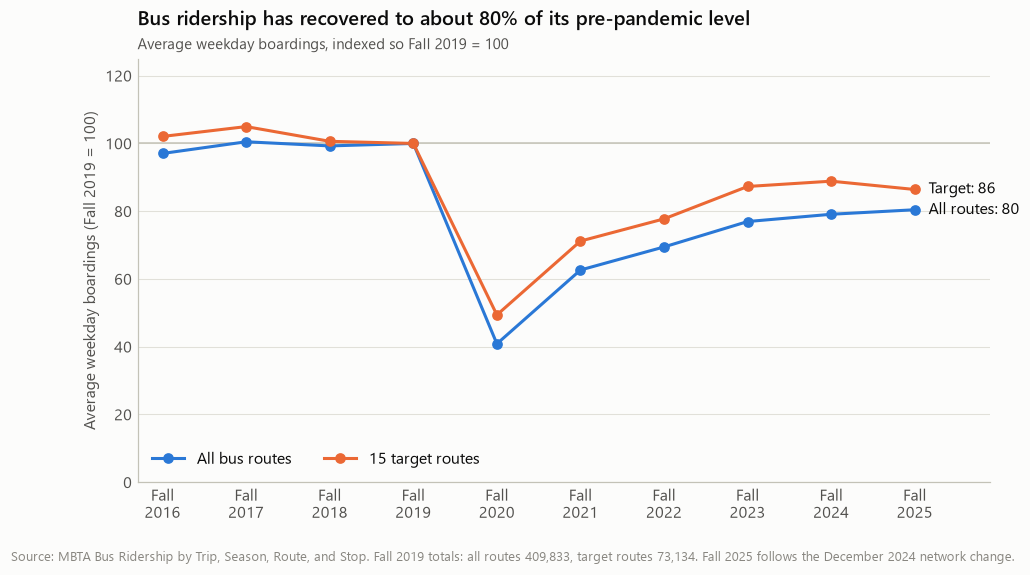

season,all routes,target routes,all (index),target (index)
Fall 2016,"397,729","74,647",97,102
Fall 2017,"411,853","76,772",100,105
Fall 2018,"406,853","73,595",99,101
Fall 2019,"409,833","73,134",100,100
Fall 2020,"167,470","36,124",41,49
Fall 2021,"256,738","52,061",63,71
Fall 2022,"284,646","56,856",69,78
Fall 2023,"315,374","63,847",77,87
Fall 2024,"324,167","64,990",79,89
Fall 2025,"329,641","63,195",80,86


In [8]:
idx_all = [sum(R[s].values()) for s in SEASONS]
idx_t = [sum(R[s].get(r, 0) for r in TARGET) for s in SEASONS]
b = SEASONS.index("Fall 2019")
ia, it = np.array(idx_all) / idx_all[b] * 100, np.array(idx_t) / idx_t[b] * 100
x = np.arange(len(SEASONS))
fig, ax = plt.subplots(figsize=(10, 5))
ax.axhline(100, color=BASELINE, lw=1)
ax.plot(x, ia, color=BLUE, lw=2, marker="o", ms=6, label="All bus routes")
ax.plot(x, it, color=ORANGE, lw=2, marker="o", ms=6, label="15 target routes")
ax.annotate(f"All routes: {ia[-1]:.0f}", (x[-1], ia[-1]), xytext=(9, 0 if abs(ia[-1]-it[-1]) > 4 else (-8 if ia[-1] < it[-1] else 8)), textcoords="offset points", va="center", color=INK)
ax.annotate(f"Target: {it[-1]:.0f}", (x[-1], it[-1]), xytext=(9, 0 if abs(ia[-1]-it[-1]) > 4 else (8 if ia[-1] < it[-1] else -8)), textcoords="offset points", va="center", color=INK)
ax.set_xticks(x, [s.replace("Fall ", "Fall\n") for s in SEASONS]); ax.set_ylim(0, 125); ax.set_xlim(-.3, len(x) - .1)
ax.set_ylabel("Average weekday boardings (Fall 2019 = 100)"); ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", ncol=2)
title(ax, 'Bus ridership has recovered to about 80% of its pre-pandemic level', "Average weekday boardings, indexed so Fall 2019 = 100")
source(fig, f"Source: MBTA Bus Ridership by Trip, Season, Route, and Stop. Fall 2019 totals: all routes {idx_all[b]:,.0f}, target routes {idx_t[b]:,.0f}. Fall 2025 follows the December 2024 network change.")
save(fig, "fig01_ridership_index.png")
show([{"season": s, "all routes": a, "target routes": t, "all (index)": i, "target (index)": j} for s, a, t, i, j in zip(SEASONS, idx_all, idx_t, ia, it)],
     fmt={"all routes": "{:,.0f}", "target routes": "{:,.0f}", "all (index)": "{:.0f}", "target (index)": "{:.0f}"})

**Verdict: supports H1.** Boardings fell to 41% of the Fall 2019 level in Fall 2020 and reached 79% in Fall 2024. Target routes recovered further, to 89% in Fall 2024, which is consistent with their riders having fewer alternatives, although this chart cannot show the reason.

**Defending this chart**
- *Why a line chart?* The question is about change over ordered time. Bars would work but make the two trends harder to compare.
- *Why an index?* The all-route total is more than five times the target-route total. Indexing puts both on one scale without a second y-axis. The table gives the raw counts.
- *Could it mislead?* The y-axis starts at 0, so the drop is not exaggerated. The index hides absolute size, so the source line states the Fall 2019 totals. Fall 2025 follows the network redesign, so it may not be fully comparable.
- *Data check:* our Fall 2018 totals are a median of 3% below the Livable Streets figures, and every route is within 14%.

### Figure 2. Ridership per route, before and after the pandemic

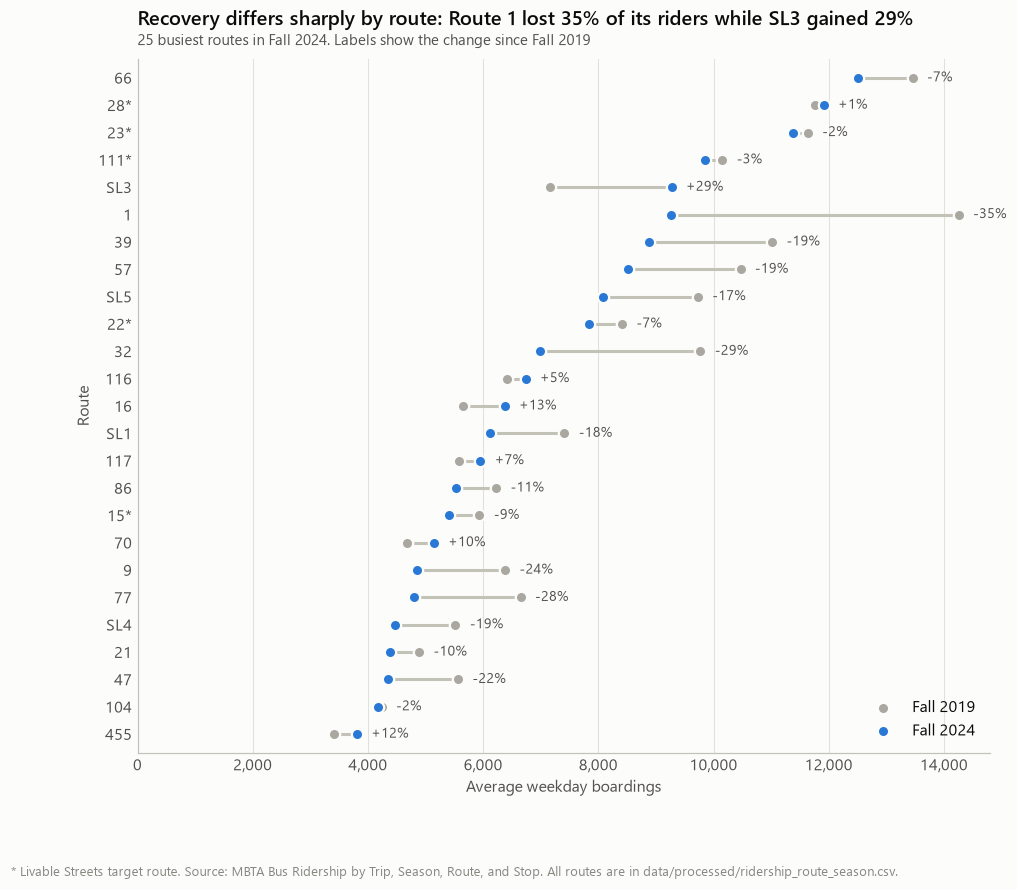

Among 127 routes with at least 500 boardings in Fall 2019: median change -20%, range -89% to +54%. 18 routes gained riders.


route,Fall 2019,Fall 2024,change %
435,627,968,+54
74,730,"1,037",+42
216,"1,044","1,449",+39
24,"1,662","2,155",+30
SL3,"7,163","9,270",+29
SLW,"2,425",876,-64
85,586,190,-68
76,979,275,-72
554,635,113,-82
55,701,78,-89


In [9]:
routes_common = [r for r in R["Fall 2019"] if r in R["Fall 2024"]]
top = sorted(routes_common, key=lambda r: -R["Fall 2024"][r])[:25][::-1]
fig, ax = plt.subplots(figsize=(10, 8.2))
for i, r in enumerate(top):
    ax.plot([R["Fall 2019"][r], R["Fall 2024"][r]], [i, i], color=BASELINE, lw=2, zorder=1)
ax.scatter([R["Fall 2019"][r] for r in top], range(len(top)), s=55, color=GRAY, zorder=2, edgecolor="#fcfcfb", lw=1.5, label="Fall 2019")
ax.scatter([R["Fall 2024"][r] for r in top], range(len(top)), s=55, color=BLUE, zorder=3, edgecolor="#fcfcfb", lw=1.5, label="Fall 2024")
for i, r in enumerate(top):
    pct = R["Fall 2024"][r] / R["Fall 2019"][r] * 100 - 100
    ax.text(max(R["Fall 2019"][r], R["Fall 2024"][r]) + 250, i, f"{pct:+.0f}%", va="center", color=INK2, fontsize=9)
ax.set_yticks(range(len(top)), [rlabel(r) for r in top]); ax.grid(axis="y", visible=False); ax.set_ylim(-.7, len(top) - .3)
ax.set_xlabel("Average weekday boardings"); ax.set_xlim(0, None); ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend(loc="lower right"); ax.set_ylabel("Route")
title(ax, 'Recovery differs sharply by route: Route 1 lost 35% of its riders while SL3 gained 29%', "25 busiest routes in Fall 2024. Labels show the change since Fall 2019")
source(fig, f"{TARGET_NOTE}. Source: MBTA Bus Ridership by Trip, Season, Route, and Stop. All routes are in data/processed/ridership_route_season.csv.")
save(fig, "fig02_ridership_by_route.png")
chg = sorted([{"route": label(r), "Fall 2019": R["Fall 2019"][r], "Fall 2024": R["Fall 2024"][r], "change %": R["Fall 2024"][r] / R["Fall 2019"][r] * 100 - 100} for r in routes_common if R["Fall 2019"][r] >= 500], key=lambda d: -d["change %"])
pcts = np.array([d["change %"] for d in chg])
print(f"Among {len(chg)} routes with at least 500 boardings in Fall 2019: median change {np.median(pcts):+.0f}%, range {pcts.min():+.0f}% to {pcts.max():+.0f}%. {int((pcts >= 0).sum())} routes gained riders.")
show(chg[:5] + chg[-5:], fmt={"Fall 2019": "{:,.0f}", "Fall 2024": "{:,.0f}", "change %": "{:+.0f}"})

**Verdict: supports H1.** Among 127 routes with at least 500 boardings in Fall 2019, the median change is -20%, and only 18 routes gained riders. Several busy target routes held almost steady (28: +1%, 23: -2%, 111: -3%), while Route 1 fell 35%.

**Defending this chart**
- *Why a dumbbell chart?* It shows both level and change for each route. Two bars per route for 25 routes would be cluttered, and a scatter plot would make it hard to read route names.
- *Why these quantities?* Fall 2019 is the last pre-pandemic fall. Fall 2024 is the last fall before the redesign, so route definitions are more comparable.
- *Could it mislead?* Selecting only the 25 busiest routes hides small routes with large percentage swings, such as Route 55 at -89%. The table lists the extremes, and the CSV has every route. Route changes between 2019 and 2024 could also explain part of a change.

### Figure 3. End-to-end travel time

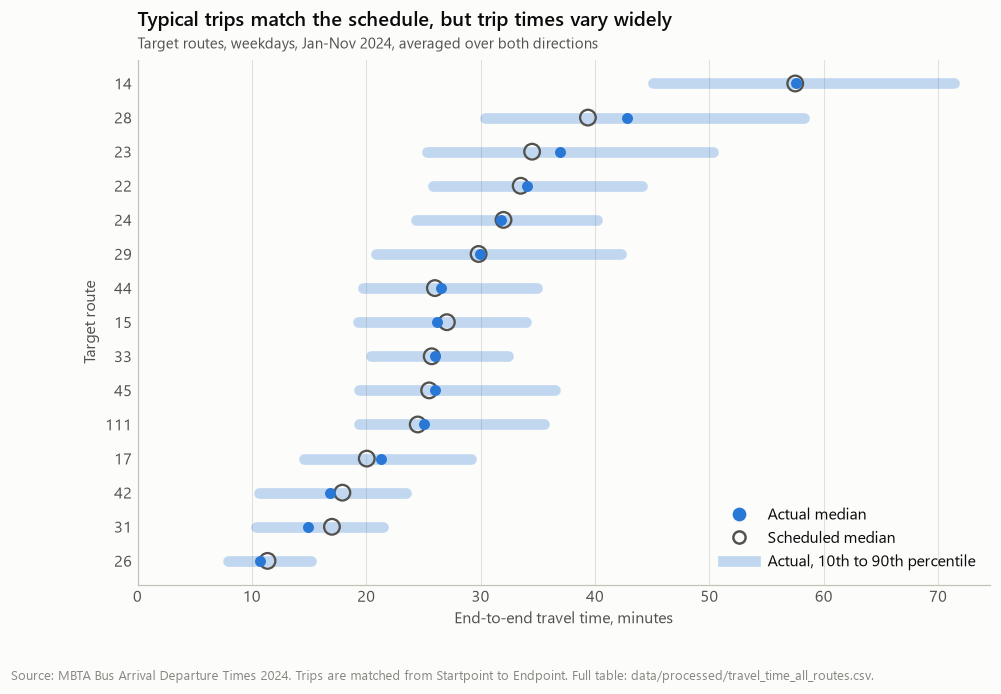

All 150 ranked routes: median actual minus scheduled = +0.1 min; median p90-p10 spread = 16.4 min (57% of the scheduled time).
Target routes: median actual minus scheduled = +0.3 min; median spread = 15.8 min.


route,trips,scheduled (min),actual median (min),p10,p90,extra vs schedule (min),p90 - p10 (min)
14,"4,248",57.5,57.6,45.0,71.4,0.1,26.3
28,"40,736",39.4,42.8,30.4,58.3,3.4,27.9
23,"46,379",34.5,36.9,25.4,50.4,2.4,25.0
22,"40,762",33.5,34.0,25.9,44.1,0.5,18.2
24,"14,636",32.0,31.7,24.4,40.1,-0.3,15.8
29,"9,290",29.8,29.9,20.8,42.3,0.1,21.4
44,"22,314",26.0,26.6,19.7,34.9,0.6,15.2
15,"39,875",27.0,26.2,19.3,34.0,-0.8,14.7
33,"9,501",25.7,26.0,20.4,32.4,0.3,12.0
45,"21,227",25.5,26.0,19.4,36.5,0.5,17.1


timepoint,mean delay (min),> 5 min late %
Startpoint,2.68,19.4
Midpoint,5.06,38.9
Endpoint,3.23,31.8


In [10]:
def travel(months):
    per = defaultdict(lambda: defaultdict(lambda: [0, 0.0, 0.0, 0.0, 0.0]))
    for x in tt:
        if x["month"] in months:
            p = per[x["route"]][x["direction"]]
            p[0] += x["trips"]; p[1] += x["trips"] * x["actual_median"]; p[2] += x["trips"] * x["actual_p10"]; p[3] += x["trips"] * x["actual_p90"]; p[4] += x["trips"] * x["scheduled_median"]
    out = {}
    for r, dirs in per.items():
        # Average monthly percentiles within a direction, then average the two directions equally.
        vals = np.array([[p[i] / p[0] for i in range(1, 5)] for p in dirs.values() if p[0]]) / 60
        out[r] = {"trips": sum(p[0] for p in dirs.values()), "actual": vals[:, 0].mean(), "p10": vals[:, 1].mean(), "p90": vals[:, 2].mean(), "scheduled": vals[:, 3].mean()}
    return out
TT24 = travel(Y24); TT20 = travel(BASE)
show_routes = sorted([r for r in TARGET if r in TT24], key=lambda r: TT24[r]["actual"])
fig, ax = plt.subplots(figsize=(10, 6.2))
for i, r in enumerate(show_routes):
    v = TT24[r]
    ax.plot([v["p10"], v["p90"]], [i, i], color=BLUE, alpha=.28, lw=7, solid_capstyle="round", zorder=1)
    ax.scatter(v["scheduled"], i, s=105, facecolor="none", edgecolor=INK2, lw=1.5, zorder=3)
    ax.scatter(v["actual"], i, s=38, color=BLUE, zorder=4)
ax.set_yticks(range(len(show_routes)), [label(r) for r in show_routes]); ax.grid(axis="y", visible=False)
ax.set_xlabel("End-to-end travel time, minutes"); ax.set_ylabel("Target route"); ax.set_xlim(0, None)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, ms=8, label="Actual median"), Line2D([], [], marker="o", ls="", mfc="#fcfcfb", mec=INK2, ms=8, mew=1.6, label="Scheduled median"),
                   Line2D([], [], color=BLUE, alpha=.28, lw=7, label="Actual, 10th to 90th percentile")], loc="lower right")
title(ax, 'Typical trips match the schedule, but trip times vary widely', "Target routes, weekdays, Jan-Nov 2024, averaged over both directions")
source(fig, "Source: MBTA Bus Arrival Departure Times 2024. Trips are matched from Startpoint to Endpoint. Full table: data/processed/travel_time_all_routes.csv.")
save(fig, "fig03_travel_time.png")
tt_all = [{"route": label(r), "trips": v["trips"], "scheduled (min)": v["scheduled"], "actual median (min)": v["actual"], "p10": v["p10"], "p90": v["p90"], "extra vs schedule (min)": v["actual"] - v["scheduled"], "p90 - p10 (min)": v["p90"] - v["p10"]}
          for r, v in sorted(TT24.items(), key=lambda kv: -kv[1]["actual"]) if r in KEPT]
write_csv(OUT / "travel_time_all_routes.csv", tt_all, list(tt_all[0]))
gap = np.array([d["extra vs schedule (min)"] for d in tt_all]); spread = np.array([d["p90 - p10 (min)"] for d in tt_all]); sc = np.array([d["scheduled (min)"] for d in tt_all])
print(f"All {len(tt_all)} ranked routes: median actual minus scheduled = {np.median(gap):+.1f} min; median p90-p10 spread = {np.median(spread):.1f} min ({np.median(spread / sc) * 100:.0f}% of the scheduled time).")
tg = [d for d in tt_all if d["route"] in TARGET]
print(f"Target routes: median actual minus scheduled = {np.median([d['extra vs schedule (min)'] for d in tg]):+.1f} min; median spread = {np.median([d['p90 - p10 (min)'] for d in tg]):.1f} min.")
show(tg, fmt={"trips": "{:,.0f}", **{c: "{:.1f}" for c in tt_all[0] if c not in ("route", "trips")}})
# Why can run times match the schedule while buses are late? Compare lateness along the trip.
show([{"timepoint": pt, "mean delay (min)": rollup(rel, Y24, types={pt})["delay_min"], "> 5 min late %": rollup(rel, Y24, types={pt})["late5"] * 100} for pt in ("Startpoint", "Midpoint", "Endpoint")], fmt={"mean delay (min)": "{:.2f}", "> 5 min late %": "{:.1f}"})

**Verdict: partly supports H2.** The typical trip is *not* much longer than scheduled: the median route is only +0.1 minutes. Routes 28 (+3.4) and 23 (+2.4) are the clear exceptions among target routes. Predictability is the bigger problem: the gap between a fast trip and a slow trip (10th to 90th percentile) is 16.4 minutes on the median route, or 57% of its scheduled time.

Delay is highest mid-route (5.1 minutes) and smaller at the destination (3.2 minutes), which suggests that buses make up time late in a trip. So on-schedule median run times can coexist with late buses.

**Defending this chart**
- *Why a range plot?* We need the typical time, the scheduled time, and the spread together. A box plot would add detail that distracts from the comparison with the schedule.
- *Why the median and percentiles?* Run times are right-skewed, and the mean would be pulled up by a few very slow trips.
- *Could it mislead?* A route's trips can follow different patterns, so some spread reflects route variants and time of day, not only unreliability. Separating these is the next step. A matching median also does not show that the schedule is good, because schedules can be padded.

### Figure 4. How long do riders wait?

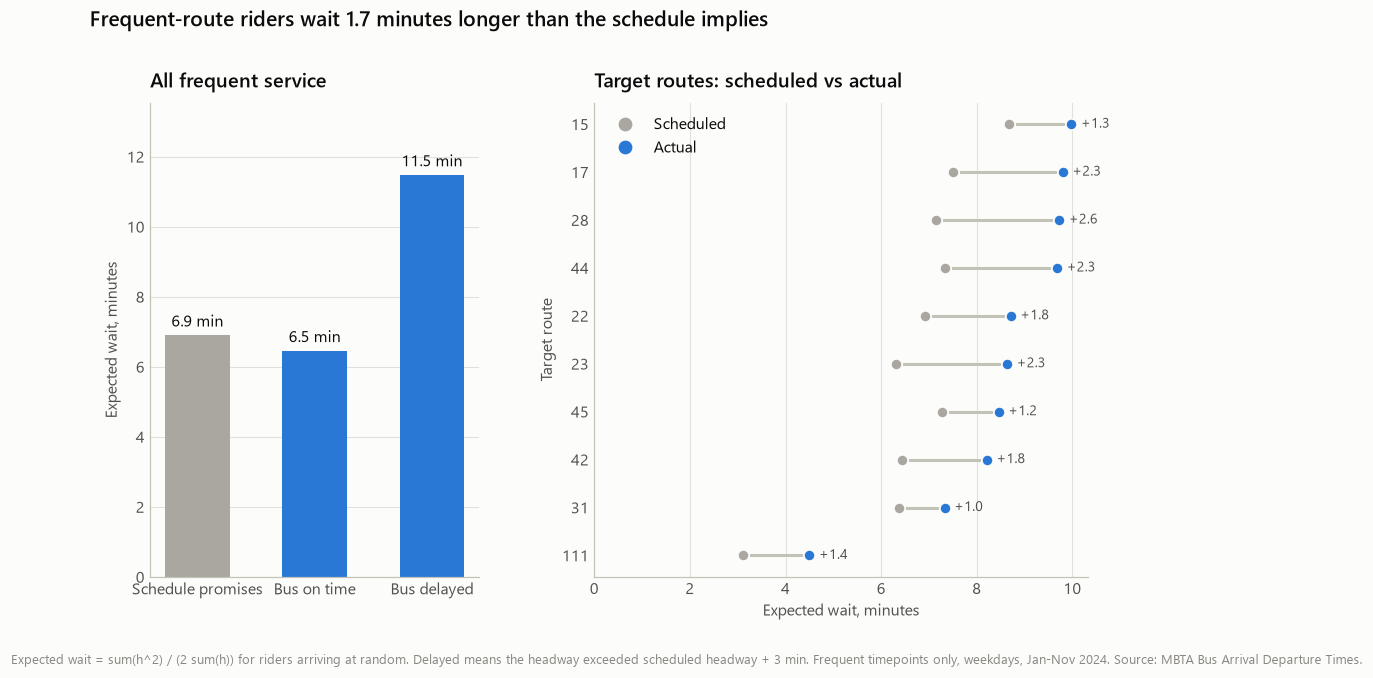

service,overall (min),scheduled (min),on-time bus (min),delayed bus (min),crossings
"Frequent, expected wait",8.6,6.9,6.5,11.5,"6,612,377"
"Scheduled, lateness past timetable",4.9,0.0,2.3,8.6,"8,624,279"


Target routes: actual 8.2 vs scheduled 6.3 min. Other routes: actual 8.8 vs scheduled 7.2 min.


In [11]:
def wait_stats(months, routes=None, status=None):
    s = [0, 0.0, 0.0, 0.0, 0.0]
    for x in wf:
        if x["month"] in months and (routes is None or x["route"] in routes) and (status is None or x["status"] == status):
            s[0] += x["n"]; s[1] += x["sum_h"]; s[2] += x["sum_h2"]; s[3] += x["sum_s"]; s[4] += x["sum_s2"]
    if not s[1] or not s[3]:
        return {"n": s[0], "actual": float("nan"), "scheduled": float("nan")}
    return {"n": s[0], "actual": s[2] / (2 * s[1]) / 60, "scheduled": s[4] / (2 * s[3]) / 60}
def sched_wait(months, routes=None, status=None):
    n = t = 0
    for x in ws:
        if x["month"] in months and (routes is None or x["route"] in routes) and (status is None or x["status"] == status):
            n += x["n"]; t += x["sum_lateness"]
    return (t / n / 60 if n else float("nan")), n

W_all, W_on, W_late = wait_stats(Y24), wait_stats(Y24, status="on_time"), wait_stats(Y24, status="delayed")
S_all, S_on, S_late = sched_wait(Y24), sched_wait(Y24, status="on_time"), sched_wait(Y24, status="delayed")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.6), gridspec_kw={"width_ratios": [1, 1.5], "wspace": .28})
cats = ["Schedule promises", "Bus on time", "Bus delayed"]
vals = [W_on["scheduled"], W_on["actual"], W_late["actual"]]
# The "schedule promises" bar uses all frequent service, so it does not depend on the on-time split.
vals[0] = W_all["scheduled"]
bars = a1.bar(cats, vals, color=[GRAY, BLUE, BLUE], width=.55)
for b_, v in zip(bars, vals):
    a1.text(b_.get_x() + b_.get_width() / 2, v + .25, f"{v:.1f} min", ha="center", color=INK)
a1.set_ylabel("Expected wait, minutes"); a1.grid(axis="x", visible=False); a1.set_ylim(0, max(vals) * 1.18)
title(a1, "All frequent service")

rt = sorted([r for r in TARGET if not math.isnan(wait_stats(Y24, {r})["actual"]) and wait_stats(Y24, {r})["n"] >= 500], key=lambda r: wait_stats(Y24, {r})["actual"])
for i, r in enumerate(rt):
    w = wait_stats(Y24, {r})
    a2.plot([w["scheduled"], w["actual"]], [i, i], color=BASELINE, lw=2, zorder=1)
    a2.scatter(w["scheduled"], i, s=55, color=GRAY, edgecolor="#fcfcfb", lw=1.2, zorder=2)
    a2.scatter(w["actual"], i, s=55, color=BLUE, edgecolor="#fcfcfb", lw=1.2, zorder=3)
    a2.text(w["actual"] + .2, i, f"+{w['actual'] - w['scheduled']:.1f}", va="center", color=INK2, fontsize=9)
a2.set_yticks(range(len(rt)), [label(r) for r in rt]); a2.grid(axis="y", visible=False); a2.set_xlim(0, None)
a2.set_xlabel("Expected wait, minutes"); a2.set_ylabel("Target route")
a2.legend(handles=[Line2D([], [], marker="o", ls="", color=GRAY, ms=8, label="Scheduled"), Line2D([], [], marker="o", ls="", color=BLUE, ms=8, label="Actual")], loc="upper left")
title(a2, "Target routes: scheduled vs actual")
fig.suptitle('Frequent-route riders wait 1.7 minutes longer than the schedule implies', x=.075, y=1.03, ha="left", fontsize=13.5, fontweight="semibold")
source(fig, "Expected wait = sum(h^2) / (2 sum(h)) for riders arriving at random. Delayed means the headway exceeded scheduled headway + 3 min. Frequent timepoints only, weekdays, Jan-Nov 2024. Source: MBTA Bus Arrival Departure Times.")
save(fig, "fig04_wait_time.png")
show([{"service": "Frequent, expected wait", "overall (min)": W_all["actual"], "scheduled (min)": W_all["scheduled"], "on-time bus (min)": W_on["actual"], "delayed bus (min)": W_late["actual"], "crossings": W_all["n"]},
      {"service": "Scheduled, lateness past timetable", "overall (min)": S_all[0], "scheduled (min)": 0.0, "on-time bus (min)": S_on[0], "delayed bus (min)": S_late[0], "crossings": S_all[1]}],
     fmt={c: "{:.1f}" for c in ("overall (min)", "scheduled (min)", "on-time bus (min)", "delayed bus (min)")} | {"crossings": "{:,.0f}"})
w_t, w_o = wait_stats(Y24, set(TARGET)), wait_stats(Y24, set(OTHER))
print(f"Target routes: actual {w_t['actual']:.1f} vs scheduled {w_t['scheduled']:.1f} min. Other routes: actual {w_o['actual']:.1f} vs scheduled {w_o['scheduled']:.1f} min.")

**Verdict: supports H3.** On frequent service, the expected wait is 8.6 minutes against 6.9 implied by the schedule. It is 6.5 minutes for a bus that meets the headway test and 11.5 minutes for one that does not. On scheduled service, the bus arrives on average 4.9 minutes after the timetable: 2.3 minutes when on time and 8.6 when delayed.

Target routes have a slightly larger excess wait (+1.9 minutes) than other routes (+1.6).

**Defending this chart**
- *Why bars on the left?* These are three separate quantities compared on a shared zero baseline, which bars show accurately.
- *Why a dumbbell on the right?* The gap between scheduled and actual is the message for each route.
- *Why this formula?* A long gap collects more riders than a short one, so half the average headway would understate what riders experience.
- *Could it mislead?* The on-time and delayed bars differ partly by definition, because "delayed" means a long gap. The chart shows how much a failure costs riders, not an independent effect. The formula also assumes random arrivals, which is less realistic if riders use real-time apps. Routes with too little frequent service are left out of the right panel.

### Figure 5. Which routes run late most often?

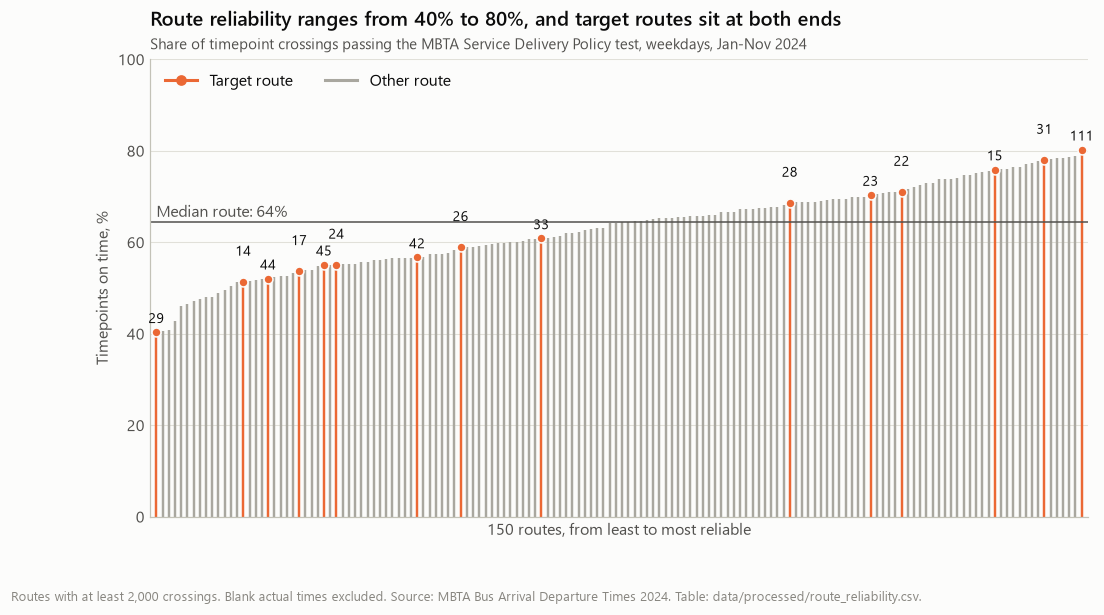

Least reliable 8:


route,on-time %,mean delay (min),> 5 min late %,blank %,boardings Fall 2024,crossings
29*,40.3,8.56,57.3,5.0,"1,219","82,199"
245,40.6,8.35,58.4,7.3,106,"17,656"
556,40.9,6.96,53.6,9.7,116,"10,009"
CT2,42.7,7.84,58.7,4.6,"1,730","123,996"
19,46.1,5.19,43.0,3.8,"2,691","143,815"
10,46.5,6.52,51.0,6.5,"2,370","139,580"
35,47.1,6.74,52.1,4.7,"1,557","91,683"
4,47.6,6.76,48.0,7.7,255,"30,044"


Route on-time rates: min 40.3%, 10th percentile 51.6%, median 64.4%, 90th percentile 75.6%, max 80.3%.
Kruskal-Wallis on daily mean delay across routes: H = 13,188, p < 1e-300.
Target minus other routes (each route counts once): on-time -1.4 pts (p = 0.591); mean delay +1.38 min (p = 0.002). 10,000 permutations.
Target route ranks from worst (1) to best (150): {'29': 1, '14': 15, '44': 19, '17': 24, '45': 28, '24': 30, '42': 43, '26': 50, '33': 63, '28': 103, '23': 116, '22': 121, '15': 136, '31': 144, '111': 150}


definition,all-route mean %,target mean %,other mean %,rank correlation with policy test
Policy test (blanks excluded),63.1,61.9,63.3,1.00
Policy test (blanks = fail),59.1,58.3,59.1,0.91
Not more than 5 min late,66.5,58.7,67.4,0.61
Not more than 10 min late,86.4,81.5,86.9,0.64


In [12]:
ranked = sorted(KEPT, key=lambda r: by_route[r]["otp"])
otps = np.array([by_route[r]["otp"] * 100 for r in ranked])
fig, ax = plt.subplots(figsize=(11, 5.4))
xs = np.arange(len(ranked))
colors = [ORANGE if r in TARGET else GRAY for r in ranked]
ax.vlines(xs, 0, otps, color=colors, lw=1.6)
ax.scatter(xs[[r in TARGET for r in ranked]], otps[[r in TARGET for r in ranked]], s=34, color=ORANGE, zorder=3, edgecolor="#fcfcfb", lw=1)
med = np.median(otps)
ax.axhline(med, color=INK2, lw=1); ax.text(0, med + 1.2, f"Median route: {med:.0f}%", ha="left", color=INK2)
tmap = {r: i for i, r in enumerate(ranked)}
targ_sorted = [r for r in ranked if r in TARGET]
for k, r in enumerate(targ_sorted):
    ax.annotate(label(r), (tmap[r], by_route[r]["otp"] * 100), xytext=(0, 6 + 11 * (k % 2)), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_xlim(-1, len(xs)); ax.set_ylim(0, 100); ax.set_xticks([]); ax.grid(axis="x", visible=False)
ax.set_ylabel("Timepoints on time, %"); ax.set_xlabel(f"{len(ranked)} routes, from least to most reliable")
ax.legend(handles=[Line2D([], [], color=ORANGE, lw=2, marker="o", ms=6, label="Target route"), Line2D([], [], color=GRAY, lw=2, label="Other route")], loc="upper left", ncol=2)
title(ax, 'Route reliability ranges from 40% to 80%, and target routes sit at both ends', "Share of timepoint crossings passing the MBTA Service Delivery Policy test, weekdays, Jan-Nov 2024")
source(fig, f"Routes with at least {MIN_N:,} crossings. Blank actual times excluded. Source: MBTA Bus Arrival Departure Times 2024. Table: data/processed/route_reliability.csv.")
save(fig, "fig05_route_reliability.png")

rt_table = [{"route": rlabel(r), "on-time %": by_route[r]["otp"] * 100, "mean delay (min)": by_route[r]["delay_min"], "> 5 min late %": by_route[r]["late5"] * 100, "blank %": by_route[r]["miss_rate"] * 100, "boardings Fall 2024": R["Fall 2024"].get(r, 0.0), "crossings": by_route[r]["n"]} for r in ranked]
write_csv(OUT / "route_reliability.csv", rt_table, list(rt_table[0]))
print("Least reliable 8:"); show(rt_table, fmt={"on-time %": "{:.1f}", "mean delay (min)": "{:.2f}", "> 5 min late %": "{:.1f}", "blank %": "{:.1f}", "boardings Fall 2024": "{:,.0f}", "crossings": "{:,.0f}"}, n=8)
p10, p90 = np.percentile(otps, [10, 90])
print(f"Route on-time rates: min {otps.min():.1f}%, 10th percentile {p10:.1f}%, median {med:.1f}%, 90th percentile {p90:.1f}%, max {otps.max():.1f}%.")
H, p_kw = stats.kruskal(*[np.array(day_means[r]) for r in KEPT if len(day_means[r]) > 5])
print(f"Kruskal-Wallis on daily mean delay across routes: H = {H:,.0f}, p {'< 1e-300' if p_kw < 1e-300 else f'= {p_kw:.1e}'}.")

# Do target routes differ from the rest? A permutation test at route level, so a route is the unit.
rng = np.random.default_rng(506)
is_t = np.array([r in TARGET for r in KEPT]); v_otp = np.array([by_route[r]["otp"] * 100 for r in KEPT]); v_del = np.array([by_route[r]["delay_min"] for r in KEPT])
def perm(v):
    obs = v[is_t].mean() - v[~is_t].mean()
    sims = np.array([(lambda p_: v[p_].mean() - v[~p_].mean())(rng.permutation(is_t)) for _ in range(10000)])
    return obs, (np.abs(sims) >= abs(obs)).mean()
o1, p1 = perm(v_otp); o2, p2 = perm(v_del)
print(f"Target minus other routes (each route counts once): on-time {o1:+.1f} pts (p = {p1:.3f}); mean delay {o2:+.2f} min (p = {p2:.3f}). 10,000 permutations.")
print(f"Target route ranks from worst (1) to best ({len(ranked)}):", {label(r): tmap[r] + 1 for r in targ_sorted})
sens = []
for nm, fn in (("Policy test (blanks excluded)", lambda r: by_route[r]["otp"]), ("Policy test (blanks = fail)", lambda r: by_route[r]["otp_missing_fail"]), ("Not more than 5 min late", lambda r: 1 - by_route[r]["late5"]), ("Not more than 10 min late", lambda r: 1 - by_route[r]["late10"])):
    v = np.array([fn(r) for r in KEPT]) * 100
    rho, _ = stats.spearmanr(v, v_otp)
    sens.append({"definition": nm, "all-route mean %": v.mean(), "target mean %": v[is_t].mean(), "other mean %": v[~is_t].mean(), "rank correlation with policy test": rho})
show(sens, fmt={"all-route mean %": "{:.1f}", "target mean %": "{:.1f}", "other mean %": "{:.1f}", "rank correlation with policy test": "{:.2f}"})

**Verdict: supports H4. H5 is mixed.** Reliability clearly differs by route: 40.3% (Route 29) to 80.3% (Route 111), with a median of 64.4%, and the differences are statistically significant (Kruskal-Wallis p < 1e-300). Of 150 ranked routes, 149 run significantly behind schedule when tested across service days.

The target routes are not uniformly worse. They rank everywhere from 1st to 150th, and their average on-time rate is not distinguishable from other routes (-1.4 points, permutation p = 0.59). They do run later on average, by 1.38 minutes (p = 0.002).

The on-time result depends on the definition: agreement with the policy ranking falls to a rank correlation of about 0.6 for simple lateness cutoffs. The sensitivity table shows this. Route 28 ranks 103rd of 150 on the policy test but has the second-highest mean delay, because 99% of its timepoints are judged on the gaps between buses.

**Defending this chart**
- *Why a ranked lollipop chart?* It shows the whole distribution and where each target route falls. A histogram would hide route identity, and a pie chart cannot show a ranking of 150 items.
- *Why these quantities?* We use the MBTA's own published standard, so the agency cannot dispute the definition.
- *Could it mislead?* Excluding blank records could flatter routes with more dropped trips, so the sensitivity table also counts blanks as failures. Very small routes can look extreme, so routes under 2,000 crossings are not ranked. The chart gives every route equal visual weight whatever its ridership; Figure 10 corrects for that.

### Figure 6. Has reliability changed over time?

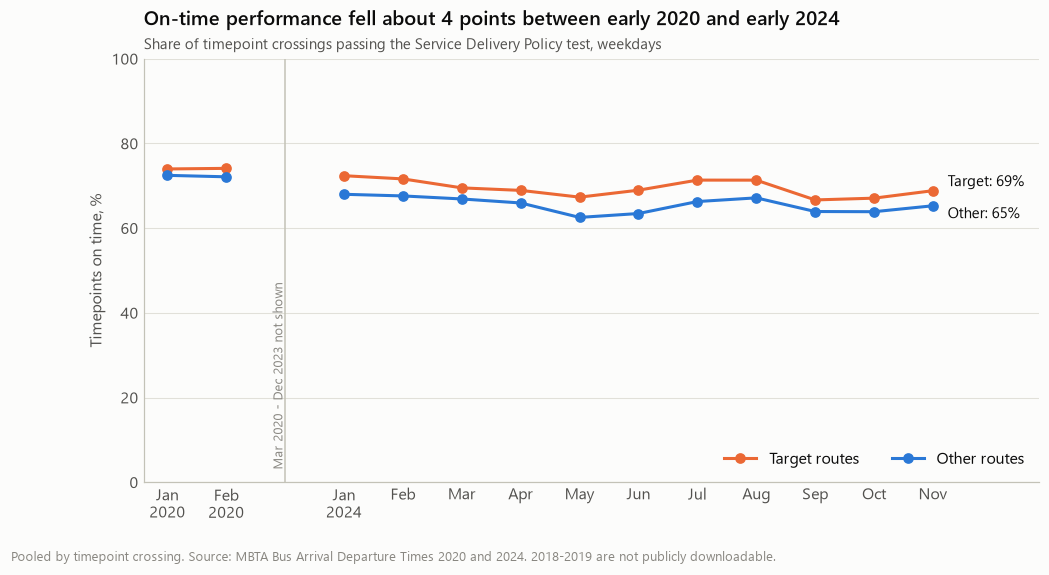

Share of crossings judged by the frequent-service test: Jan-Feb 2020 49%, Jan-Feb 2024 44%.


group,on-time Jan-Feb 2020,on-time Jan-Feb 2024,change (pts),delay 2020 (min),delay 2024 (min),blank 2020 %,blank 2024 %
All routes,72.6,68.6,-4.0,2.26,3.85,5.2,7.3
Target routes,74.0,72.0,-2.0,2.44,4.18,4.5,7.2
Other routes,72.3,67.8,-4.5,2.22,3.77,5.3,7.3


Target routes, Jan-Feb median end-to-end time: 26.6 min in 2020, 26.9 min in 2024. Schedule: 26.9 and 27.6 min.


In [13]:
months24 = sorted(Y24); labels24 = [date(2024, int(m[-2:]), 1).strftime("%b") for m in months24]
fig, ax = plt.subplots(figsize=(10.5, 5))
xb = np.array([0, 1]); xm = np.arange(len(months24)) + 3
series = [("Target routes", set(TARGET), ORANGE), ("Other routes", set(OTHER), BLUE)]
end = {}
for nm, rs, c in series:
    yb = [rollup(rel, {m}, rs)["otp"] * 100 for m in sorted(BASE)]
    ym = [rollup(rel, {m}, rs)["otp"] * 100 for m in months24]
    ax.plot(xb, yb, color=c, lw=2, marker="o", ms=6); ax.plot(xm, ym, color=c, lw=2, marker="o", ms=6, label=nm)
    end[nm] = ym[-1]
    ax.text(xm[-1] + .25, ym[-1] + (2 if nm == "Target routes" else -2), f"{nm.split()[0]}: {ym[-1]:.0f}%", va="center", color=INK, fontsize=9.5)
ax.axvline(2, color=BASELINE, lw=1)
ax.text(2, 3, "Mar 2020 - Dec 2023 not shown", rotation=90, va="bottom", ha="right", color=MUTED, fontsize=8.5)
ax.set_xticks(np.r_[xb, xm], ["Jan\n2020", "Feb\n2020"] + [l + ("\n2024" if i == 0 else "") for i, l in enumerate(labels24)])
ax.set_ylim(0, 100); ax.set_xlim(-.4, xm[-1] + 1.8); ax.grid(axis="x", visible=False); ax.set_ylabel("Timepoints on time, %")
ax.legend(loc="lower right", ncol=2)
title(ax, 'On-time performance fell about 4 points between early 2020 and early 2024', "Share of timepoint crossings passing the Service Delivery Policy test, weekdays")
source(fig, "Pooled by timepoint crossing. Source: MBTA Bus Arrival Departure Times 2020 and 2024. 2018-2019 are not publicly downloadable.")
save(fig, "fig06_reliability_over_time.png")
cmp_rows = []
for nm, rs in (("All routes", None), ("Target routes", set(TARGET)), ("Other routes", set(OTHER))):
    a, b_ = rollup(rel, BASE, rs), rollup(rel, JF24, rs)
    cmp_rows.append({"group": nm, "on-time Jan-Feb 2020": a["otp"] * 100, "on-time Jan-Feb 2024": b_["otp"] * 100, "change (pts)": (b_["otp"] - a["otp"]) * 100, "delay 2020 (min)": a["delay_min"], "delay 2024 (min)": b_["delay_min"], "blank 2020 %": a["miss_rate"] * 100, "blank 2024 %": b_["miss_rate"] * 100})
mix = lambda months: sum(x["n"] for x in rel if x["month"] in months and x["standard"] == "Headway") / sum(x["n"] for x in rel if x["month"] in months)
print(f"Share of crossings judged by the frequent-service test: Jan-Feb 2020 {mix(BASE):.0%}, Jan-Feb 2024 {mix(JF24):.0%}.")
show(cmp_rows, fmt={c: "{:.1f}" for c in cmp_rows[0] if c != "group"} | {"change (pts)": "{:+.1f}", "delay 2020 (min)": "{:.2f}", "delay 2024 (min)": "{:.2f}"})
tt_cmp = []
J24 = travel(JF24)
for r in TARGET:
    if r in TT20 and r in J24:
        tt_cmp.append({"route": r, "actual 2020 (min)": TT20[r]["actual"], "actual 2024 (min)": J24[r]["actual"], "scheduled 2020": TT20[r]["scheduled"], "scheduled 2024": J24[r]["scheduled"]})
print(f"Target routes, Jan-Feb median end-to-end time: {np.mean([d['actual 2020 (min)'] for d in tt_cmp]):.1f} min in 2020, {np.mean([d['actual 2024 (min)'] for d in tt_cmp]):.1f} min in 2024. Schedule: {np.mean([d['scheduled 2020'] for d in tt_cmp]):.1f} and {np.mean([d['scheduled 2024'] for d in tt_cmp]):.1f} min.")

**Verdict: supports the claim that service worsened, with caveats.** Comparing the same months, the on-time rate fell from 72.6% to 68.6%, and mean delay rose from 2.26 to 3.85 minutes. The decline is larger on other routes (-4.5 points) than on target routes (-2.0). Within 2024, the all-route rate ranged from 63.5% in May to 68.9% in January, so the Jan-Nov average of 66.3% is lower than the January-February comparison suggests.

**Defending this chart**
- *Why a line chart with a break?* Monthly values are ordered in time. The break makes it explicit that we have no data on this chart for March 2020 to December 2023, and a connecting line would imply a trend we did not measure.
- *Why January and February?* They are the only clean pre-COVID months available, and comparing the same months in 2024 removes season as an explanation.
- *Could it mislead?* Two months is a thin baseline, and 2018 was not publicly available. The mix of service also shifted: 49% of crossings used the frequent-service test in 2020 against 44% in 2024, so mean delay is a useful second check. Blank records rose from 5.2% to 7.3%. The target line is pooled by crossing, so it is pulled up by busy, reliable routes such as 111. This is why target routes look better here than in the route-average comparison under Figure 5.

### Figure 7. Where is service unreliable, and who lives there?

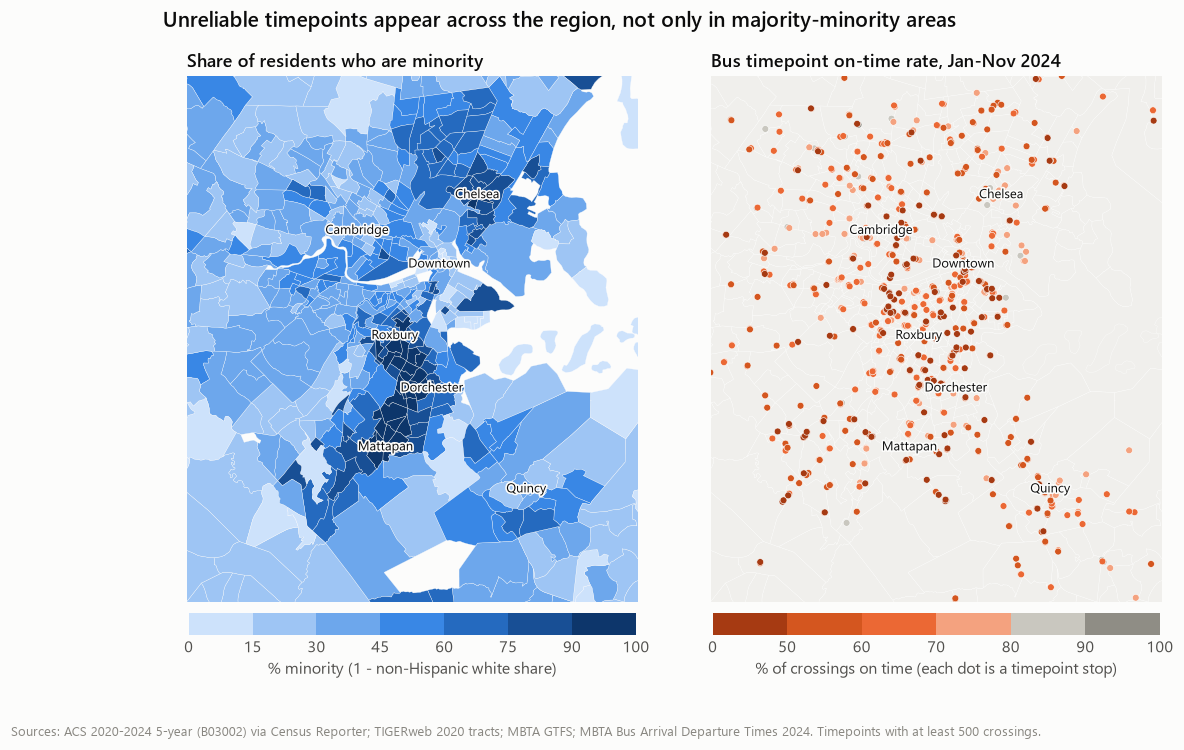

1031 timepoint stops mapped. Under 60% on time: 407.


In [14]:
XLIM, YLIM = (-71.22, -70.93), (42.20, 42.45)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6.6), gridspec_kw={"wspace": .05})
bins = [0, 15, 30, 45, 60, 75, 90, 100]
cmap, norm = ListedColormap(SEQ_BLUE), BoundaryNorm(bins, 7)
verts, cols, outline = [], [], []
for t in TR:
    for poly in t["polys"]:
        outline.append(np.array(poly[0]))
        if t["geoid"] in ACS:
            verts.append(np.array(poly[0])); cols.append(ACS[t["geoid"]]["minority"])
pc = PolyCollection(verts, array=np.array(cols), cmap=cmap, norm=norm, edgecolor="#fcfcfb", linewidth=.2)
a1.add_collection(pc)
a2.add_collection(PolyCollection(outline, facecolor="#f0efec", edgecolor="#fcfcfb", linewidth=.25))
pts = [(STOPS[x["stop_id"]], 100 * x["on_time"] / x["n"], x["n"]) for x in s24 if x["stop_id"] in STOPS and x["n"] >= 500 and tract_of.get(x["stop_id"])]
xy = np.array([p[0] for p in pts]); val = np.array([p[1] for p in pts])
ot_bins = [0, 50, 60, 70, 80, 90, 100]
ot_cmap, ot_norm = ListedColormap(["#a63a12", "#d4561f", "#eb6834", "#f4a27f", "#c9c7bf", "#8f8d85"]), BoundaryNorm(ot_bins, 6)
order = np.argsort(-val)
sc_ = a2.scatter(xy[order, 0], xy[order, 1], c=val[order], cmap=ot_cmap, norm=ot_norm, s=20, edgecolor="#fcfcfb", linewidth=.4)
for a, t_ in ((a1, "Share of residents who are minority"), (a2, "Bus timepoint on-time rate, Jan-Nov 2024")):
    a.set_xlim(XLIM); a.set_ylim(YLIM); a.set_aspect(1 / math.cos(math.radians(42.3))); a.set_xticks([]); a.set_yticks([]); a.grid(False)
    for s_ in a.spines.values():
        s_.set_visible(False)
    a.set_title(t_, fontsize=11.5)
for a in (a1, a2):
    for nm, lon, lat in (("Downtown", -71.058, 42.359), ("Roxbury", -71.086, 42.325), ("Dorchester", -71.062, 42.300), ("Mattapan", -71.092, 42.272), ("Cambridge", -71.11, 42.375), ("Chelsea", -71.033, 42.392), ("Quincy", -71.002, 42.252)):
        a.text(lon, lat, nm, fontsize=8.5, color=INK, ha="center", path_effects=[__import__("matplotlib.patheffects", fromlist=["x"]).withStroke(linewidth=2.2, foreground="#fcfcfb")])
c1 = fig.colorbar(pc, ax=a1, orientation="horizontal", fraction=.04, pad=.02, ticks=bins); c1.outline.set_visible(False); c1.set_label("% minority (1 - non-Hispanic white share)")
c2 = fig.colorbar(sc_, ax=a2, orientation="horizontal", fraction=.04, pad=.02, ticks=ot_bins); c2.outline.set_visible(False); c2.set_label("% of crossings on time (each dot is a timepoint stop)")
fig.suptitle('Unreliable timepoints appear across the region, not only in majority-minority areas', x=.125, y=.97, ha="left", fontsize=13.5, fontweight="semibold")
source(fig, f"Sources: ACS {acs_raw['release']['years']} 5-year (B03002) via Census Reporter; TIGERweb 2020 tracts; MBTA GTFS; MBTA Bus Arrival Departure Times 2024. Timepoints with at least 500 crossings.")
save(fig, "fig07_map.png")
print(f"{len(pts)} timepoint stops mapped. Under 60% on time: {(val < 60).sum()}.")

**Verdict: challenges a simple reading of H6.** Mapped side by side, poor on-time rates are not confined to majority-minority neighborhoods such as Roxbury, Dorchester, and Mattapan. Of 1,031 mapped timepoints, 407 are under 60% on time, and they appear throughout the service area. Figures 8 and 9 test this formally.

**Defending this chart**
- *Why two maps?* The project asks about geography, and overlaying both variables on one map would be unreadable. A shared extent makes the same place easy to find on each panel.
- *Why tracts and timepoints?* Demographics are published by tract. Reliability exists only at timepoints, so dots avoid suggesting we have measurements for an entire tract.
- *Why fixed color bins?* Bins can be read against the legend, and seven or fewer classes stay distinguishable.
- *Could it mislead?* Large suburban tracts draw the eye regardless of population. Overlapping dots can hide values downtown, so the best-performing timepoints are drawn first and the worst last. A map also shows only visual association, so it needs the statistics in Figure 9.

### Figure 8. Do minority and low-income riders get worse service?

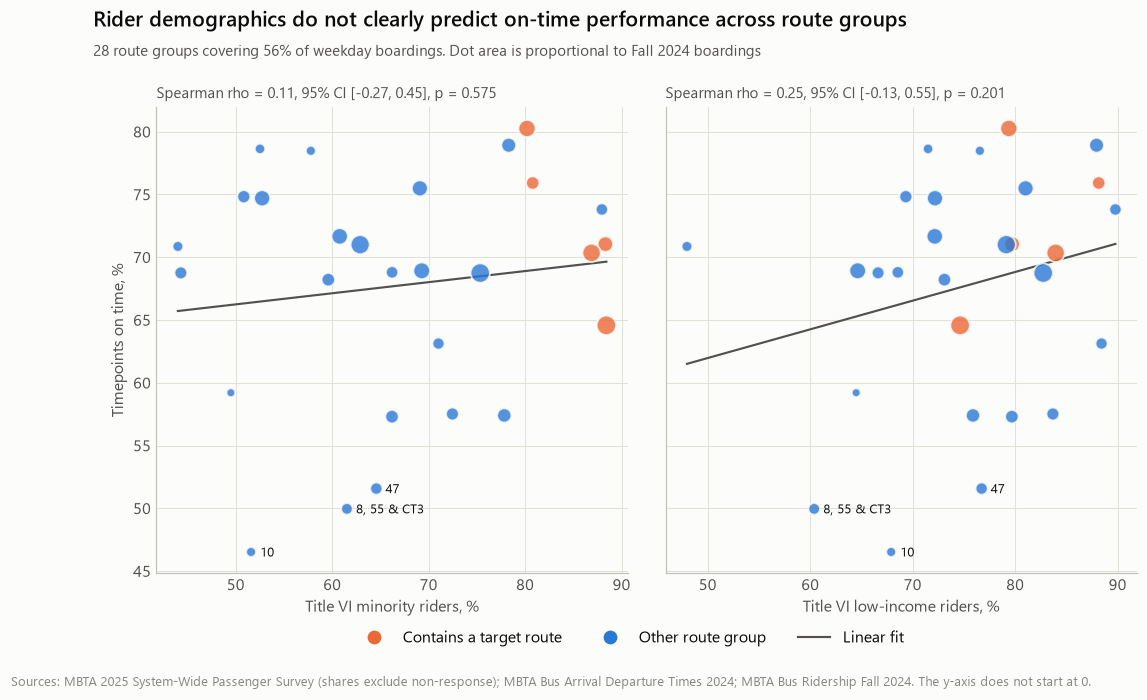

comparison,group rate %,comparison rate %,difference (pts),95% CI low,95% CI high
Minority vs Non-minority,69.1,68.8,+0.3,-1.0,+1.7
Low-income vs Not low-income,69.2,68.4,+0.8,-0.2,+1.9


Against mean delay instead of on-time rate: minority rho = 0.08 (p = 0.670); low-income rho = -0.31 (p = 0.105).
Slopes (on-time points per +10 pts of group share): {'minority': np.float64(0.88), 'low_income': np.float64(2.28)}


In [15]:
def rho_ci(x, y, n_boot=5000, seed=506):
    x, y = np.asarray(x), np.asarray(y); rng = np.random.default_rng(seed)
    r_, p_ = stats.spearmanr(x, y)
    boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x))
        if len(set(x[i])) > 2:
            boots.append(stats.spearmanr(x[i], y[i])[0])
    return r_, p_, np.percentile(boots, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.5), sharey=True, gridspec_kw={"wspace": .08})
res = {}
for ax, key, nm in zip(axes, ("minority", "low_income"), ("Title VI minority riders, %", "Title VI low-income riders, %")):
    x = np.array([e[key] for e in equity]); y = np.array([e["otp"] for e in equity]); sz = np.array([e["boardings"] for e in equity])
    c = [ORANGE if e["is_target"] else BLUE for e in equity]
    ax.scatter(x, y, s=sz / 90 + 15, c=c, alpha=.8, edgecolor="#fcfcfb", lw=1.2, zorder=3)
    m_, b_ = np.polyfit(x, y, 1); xx = np.array([x.min(), x.max()])
    ax.plot(xx, m_ * xx + b_, color=INK2, lw=1.4, zorder=2)
    r_, p_, ci = rho_ci(x, y); res[key] = (r_, p_, ci, m_)
    ax.set_title(f"Spearman rho = {r_:.2f}, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}], p = {p_:.3f}", fontsize=10, fontweight="normal", color=INK2)
    ax.set_xlabel(nm)
    idx = sorted(range(len(equity)), key=lambda i: y[i])[:3]
    for i in idx:
        ax.annotate(equity[i]["group"], (x[i], y[i]), xytext=(6, -3), textcoords="offset points", fontsize=8.5, color=INK)
axes[0].set_ylabel("Timepoints on time, %")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=ORANGE, ms=8, label="Contains a target route"), Line2D([], [], marker="o", ls="", color=BLUE, ms=8, label="Other route group"), Line2D([], [], color=INK2, lw=1.4, label="Linear fit")], loc="lower center", ncol=3, bbox_to_anchor=(.5, -.035))
fig.suptitle('Rider demographics do not clearly predict on-time performance across route groups', x=.075, y=1.04, ha="left", fontsize=13.5, fontweight="semibold")
fig.text(.075, .965, f"{len(equity)} route groups covering {cov:.0%} of weekday boardings. Dot area is proportional to Fall 2024 boardings", color=INK2, fontsize=10)
fig.text(.01, -.06, "Sources: MBTA 2025 System-Wide Passenger Survey (shares exclude non-response); MBTA Bus Arrival Departure Times 2024; MBTA Bus Ridership Fall 2024. The y-axis does not start at 0.", color=MUTED, fontsize=8.5, va="top")
save(fig, "fig08_equity_routes.png")

# Rider-weighted view: the average on-time rate experienced by a rider in each group, with a route-level bootstrap.
def exposure(key, seed=506, n_boot=5000):
    p = np.array([e[key] / 100 for e in equity]); w = np.array([e["boardings"] for e in equity]); y = np.array([e["otp"] for e in equity])
    def f(i):
        return (w[i] * p[i] * y[i]).sum() / (w[i] * p[i]).sum(), (w[i] * (1 - p[i]) * y[i]).sum() / (w[i] * (1 - p[i])).sum()
    a, b_ = f(np.arange(len(y))); rng = np.random.default_rng(seed)
    d = [np.subtract(*f(rng.integers(0, len(y), len(y)))) for _ in range(n_boot)]
    return a, b_, a - b_, *np.percentile(d, [2.5, 97.5])
ex = []
for key, a_, b_ in (("minority", "Minority", "Non-minority"), ("low_income", "Low-income", "Not low-income")):
    u, v, d, lo, hi = exposure(key)
    ex.append({"comparison": f"{a_} vs {b_}", "group rate %": u, "comparison rate %": v, "difference (pts)": d, "95% CI low": lo, "95% CI high": hi})
show(ex, fmt={"group rate %": "{:.1f}", "comparison rate %": "{:.1f}", "difference (pts)": "{:+.1f}", "95% CI low": "{:+.1f}", "95% CI high": "{:+.1f}"})
xm_, ym_, xl_, yl_ = [e["minority"] for e in equity], [e["delay"] for e in equity], [e["low_income"] for e in equity], [e["delay"] for e in equity]
print(f"Against mean delay instead of on-time rate: minority rho = {stats.spearmanr(xm_, ym_)[0]:.2f} (p = {stats.spearmanr(xm_, ym_)[1]:.3f}); low-income rho = {stats.spearmanr(xl_, yl_)[0]:.2f} (p = {stats.spearmanr(xl_, yl_)[1]:.3f}).")
print("Slopes (on-time points per +10 pts of group share):", {k: round(v[3] * 10, 2) for k, v in res.items()})

**Verdict: does not support H6 at this level, but the test is weak.** Across 28 route groups, minority share and on-time rate have a Spearman correlation of 0.11, and low-income share 0.25. Both confidence intervals include zero. A rider-weighted comparison agrees: the average minority rider's bus is on time 69.1% of the time, against 68.8% for non-minority riders (difference +0.3 points, 95% CI -1.0 to +1.7).

**Defending this chart**
- *Why a scatter plot?* We are asking whether two numeric variables move together across routes, which is what a scatter plot shows. Bars would hide this relationship.
- *Why survey data?* It describes the people who actually ride each route, which census data cannot do.
- *Could it mislead?* Yes, in several ways. Only 28 groups are included, so the wide intervals mean we cannot rule out a moderate relationship. The sample covers 56% of boardings, because 16 groups named after places, including the Roxbury, Dorchester, and Mattapan groups, do not list their routes. The missing groups are the most relevant to this question. The fitted line can also look more certain than the data supports, so the correlation and interval are printed above each panel. The y-axis does not start at 0, because the question is about position and not magnitude. Route averages also cannot tell us about the experience of individual riders.

### Figure 9. The same question by neighborhood

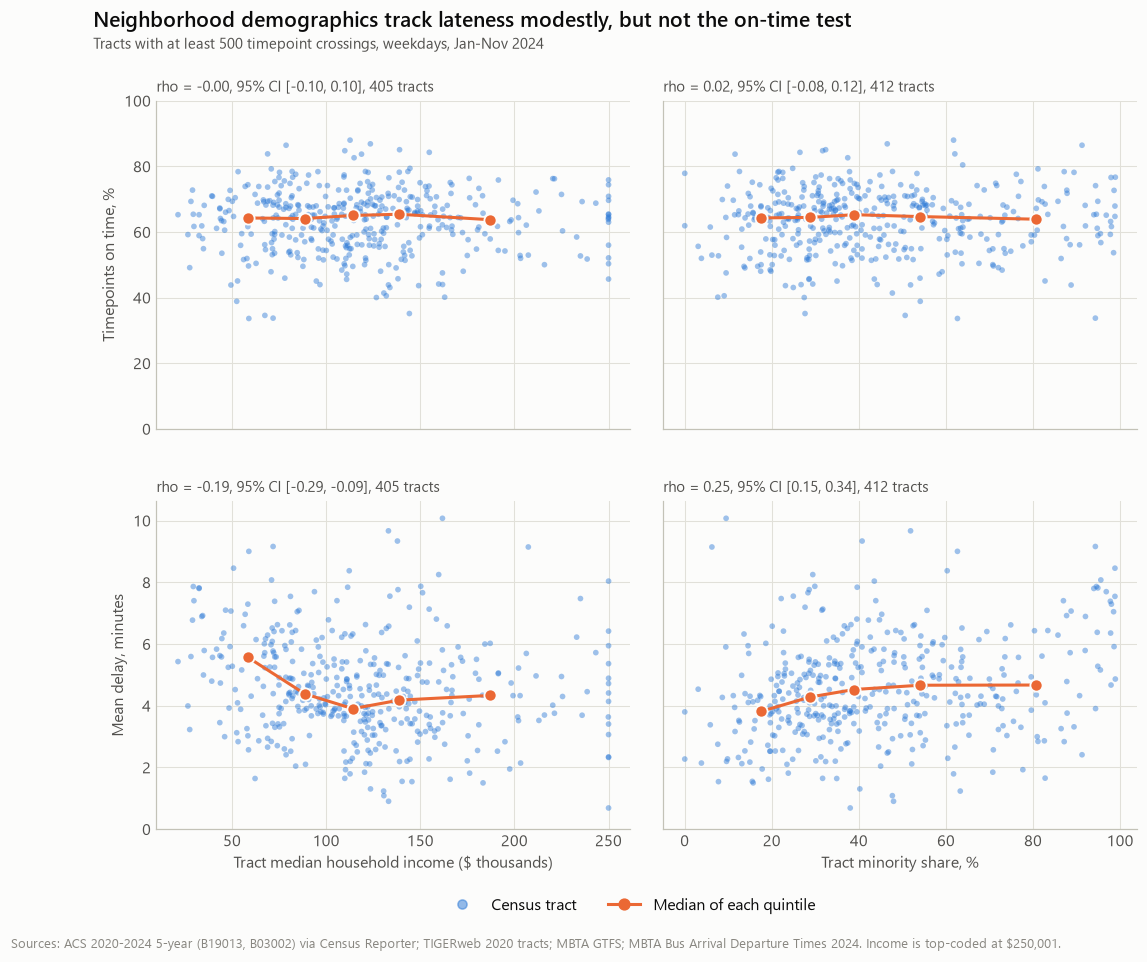

('otp', 'income') rho -0.002 p 9.67e-01 CI [-0.1  0.1] quintile medians (x, y): [(58.4, 64.29), (88.6, 64.11), (114.1, 65.05), (138.8, 65.43), (187.1, 63.76)]
('otp', 'minority') rho 0.021 p 6.68e-01 CI [-0.08  0.12] quintile medians (x, y): [(17.5, 64.31), (28.8, 64.45), (38.9, 65.29), (54.1, 64.71), (80.7, 63.91)]
('delay', 'income') rho -0.194 p 8.41e-05 CI [-0.29 -0.09] quintile medians (x, y): [(58.4, 5.57), (88.6, 4.39), (114.1, 3.91), (138.8, 4.18), (187.1, 4.33)]
('delay', 'minority') rho 0.248 p 3.59e-07 CI [0.15 0.34] quintile medians (x, y): [(17.5, 3.82), (28.8, 4.28), (38.9, 4.53), (54.1, 4.67), (80.7, 4.67)]

All 147 ranked routes, boardings-weighted neighborhood profile (97% of boardings located in a tract):
  Income vs on-time: rho = 0.16, p = 0.052
  Minority share vs on-time: rho = -0.15, p = 0.068
  Income vs mean delay: rho = -0.23, p = 0.004
  Minority share vs mean delay: rho = 0.20, p = 0.013
  Minority share vs > 5 min late: rho = 0.22, p = 0.006
  Five route-le

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.6), sharex="col", sharey="row", gridspec_kw={"wspace": .07, "hspace": .22})
TI = [t for t in TRACT if t["income"]]
pairs = [("income", "Tract median household income ($ thousands)", TI, lambda v: v / 1000), ("minority", "Tract minority share, %", TRACT, lambda v: v)]
measures = [("otp", "Timepoints on time, %", (0, 100)), ("delay", "Mean delay, minutes", (None, None))]
tr_res = {}
for row, (mkey, mname, ylim) in enumerate(measures):
    for col, (key, nm, rows, tf) in enumerate(pairs):
        ax = axes[row, col]
        x = np.array([tf(t[key]) for t in rows]); y = np.array([t[mkey] for t in rows])
        ax.scatter(x, y, s=14, color=BLUE, alpha=.45, edgecolor="none", zorder=2)
        # Quintile medians show the trend without assuming a straight line.
        qs = np.percentile(x, [0, 20, 40, 60, 80, 100]); q = np.clip(np.searchsorted(qs, x, side="right") - 1, 0, 4)
        mx = [np.median(x[q == k]) for k in range(5)]; my = [np.median(y[q == k]) for k in range(5)]
        ax.plot(mx, my, color=ORANGE, lw=2, marker="o", ms=8, mec="#fcfcfb", mew=1.2, zorder=3)
        r_, p_, ci = rho_ci(x, y); tr_res[(mkey, key)] = (r_, p_, ci, list(zip(mx, my)), len(rows))
        ax.set_title(f"rho = {r_:.2f}, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}], {len(rows)} tracts", fontsize=10, fontweight="normal", color=INK2)
        if row == 1:
            ax.set_xlabel(nm)
        if col == 0:
            ax.set_ylabel(mname)
    if ylim[0] is not None:
        axes[row, 0].set_ylim(ylim)
    else:
        axes[row, 0].set_ylim(0, None)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, alpha=.5, ms=6, label="Census tract"), Line2D([], [], color=ORANGE, lw=2, marker="o", ms=7, label="Median of each quintile")], loc="lower center", ncol=2, bbox_to_anchor=(.5, .005))
fig.suptitle('Neighborhood demographics track lateness modestly, but not the on-time test', x=.075, y=.975, ha="left", fontsize=13.5, fontweight="semibold")
fig.text(.075, .935, "Tracts with at least 500 timepoint crossings, weekdays, Jan-Nov 2024", color=INK2, fontsize=10)
fig.text(.01, -.005, f"Sources: ACS {acs_raw['release']['years']} 5-year (B19013, B03002) via Census Reporter; TIGERweb 2020 tracts; MBTA GTFS; MBTA Bus Arrival Departure Times 2024. Income is top-coded at $250,001.", color=MUTED, fontsize=8.5, va="top")
save(fig, "fig09_equity_tracts.png")
for k, v in tr_res.items():
    print(k, "rho", round(float(v[0]), 3), "p", f"{v[1]:.2e}", "CI", np.round(v[2], 2), "quintile medians (x, y):", [(round(float(a), 1), round(float(b), 2)) for a, b in v[3]])

# Route level with ACS: each route's neighborhood is the boardings-weighted average across its stops.
r_income, r_min = defaultdict(lambda: [0.0, 0.0]), defaultdict(lambda: [0.0, 0.0])
for x in ride_stop:
    if x["season"] == "Fall 2024" and x["boardings"] > 0:
        g = tract_of.get(x["stop_id"])
        if g in ACS:
            if ACS[g]["income"]:
                r_income[x["route"]][0] += x["boardings"] * ACS[g]["income"]; r_income[x["route"]][1] += x["boardings"]
            r_min[x["route"]][0] += x["boardings"] * ACS[g]["minority"]; r_min[x["route"]][1] += x["boardings"]
matched_b = sum(v[1] for v in r_min.values()) / sum(BOARD.values())
rr = [r for r in KEPT if r_income[r][1] and r_min[r][1]]
ri, rm, ro = [np.array(v) for v in ([r_income[r][0] / r_income[r][1] for r in rr], [r_min[r][0] / r_min[r][1] for r in rr], [by_route[r]["otp"] * 100 for r in rr])]
print(f"\nAll {len(rr)} ranked routes, boardings-weighted neighborhood profile ({matched_b:.0%} of boardings located in a tract):")
print(f"  Income vs on-time: rho = {stats.spearmanr(ri, ro)[0]:.2f}, p = {stats.spearmanr(ri, ro)[1]:.3f}")
print(f"  Minority share vs on-time: rho = {stats.spearmanr(rm, ro)[0]:.2f}, p = {stats.spearmanr(rm, ro)[1]:.3f}")
rd_ = np.array([by_route[r]["delay_min"] for r in rr]); r5 = np.array([by_route[r]["late5"] * 100 for r in rr])
print(f"  Income vs mean delay: rho = {stats.spearmanr(ri, rd_)[0]:.2f}, p = {stats.spearmanr(ri, rd_)[1]:.3f}")
print(f"  Minority share vs mean delay: rho = {stats.spearmanr(rm, rd_)[0]:.2f}, p = {stats.spearmanr(rm, rd_)[1]:.3f}")
print(f"  Minority share vs > 5 min late: rho = {stats.spearmanr(rm, r5)[0]:.2f}, p = {stats.spearmanr(rm, r5)[1]:.3f}")
print("  Five route-level tests were run here; a Bonferroni threshold would be p < 0.01.")
hi = sorted(rr, key=lambda r: -(r_min[r][0] / r_min[r][1]))
q = len(hi) // 4
for nm, grp in (("Most-minority quarter of routes", hi[:q]), ("Least-minority quarter of routes", hi[-q:])):
    g_ = set(grp); w_ = wait_stats(Y24, g_)
    fq = sum(x["n"] for x in rel if x["month"] in Y24 and x["route"] in g_ and x["standard"] == "Headway") / rollup(rel, Y24, g_)["n"]
    print(f"{nm}: on-time {rollup(rel, Y24, g_)['otp']:.1%}, mean delay {rollup(rel, Y24, g_)['delay_min']:.2f} min, > 5 min late {rollup(rel, Y24, g_)['late5']:.1%}, frequent-test share {fq:.0%}, expected wait {w_['actual']:.1f} vs scheduled {w_['scheduled']:.1f} min (excess {w_['actual'] - w_['scheduled']:.1f}), boardings share {sum(BOARD.get(r, 0) for r in grp) / sum(BOARD.values()):.0%}")

**Verdict: partly supports H6.** The answer depends on the measure.

- **On-time test:** there is no relationship with tract income (rho = 0.00) or minority share (rho = 0.02).
- **Mean delay:** there is a modest relationship. It rises with tract minority share (rho = 0.25, 95% CI 0.15 to 0.34) and falls as income rises (rho = -0.19, 95% CI -0.29 to -0.09). The lowest-income fifth of tracts has a median delay of 5.6 minutes, against 3.9 to 4.4 for the other four.
- **Routes:** on the 147 ranked routes, the most-minority quarter averages 4.88 minutes of delay and the least-minority quarter 3.85, even though their on-time rates are nearly equal (67.8% and 67.9%).

**Why the two measures disagree.** In the most-minority quarter of routes, 60% of crossings use the frequent-service test, against 37% in the least-minority quarter. That test measures the gap between buses, so a route can run late against its timetable and still pass. Excess wait, the measure closest to the experience on frequent routes, is also slightly higher on the most-minority routes (+1.7 minutes vs +1.3). This is an important question for the MBTA standard itself, but it does not prove the standard is biased.

**Defending this chart**
- *Why a 2 x 2 scatter grid?* It places both measures against both demographics on a shared layout, so the contrast between rows is the main message.
- *Why quintile medians?* They show the trend without assuming a straight line, as the income panel demonstrates: most of the delay gap is in the lowest-income fifth.
- *Why Spearman correlation?* It handles skewed income and does not assume a straight-line relationship.
- *Could it mislead?* These correlations are modest and do not show cause. Traffic and street design are likely confounders, since dense neighborhoods can have both more congestion and more minority residents. Timepoints also describe where buses are measured, and that is not always where affected riders live. Mean delay matters less to riders on frequent routes, so it should be read together with wait. Finally, we ran several tests, so the weakest results deserve caution; on routes, the minority-delay correlation (p = 0.013) does not pass a Bonferroni threshold of 0.01, though the income-delay (p = 0.004) and minority-late-share (p = 0.006) results do.

### Figure 10. Who loses the most time?

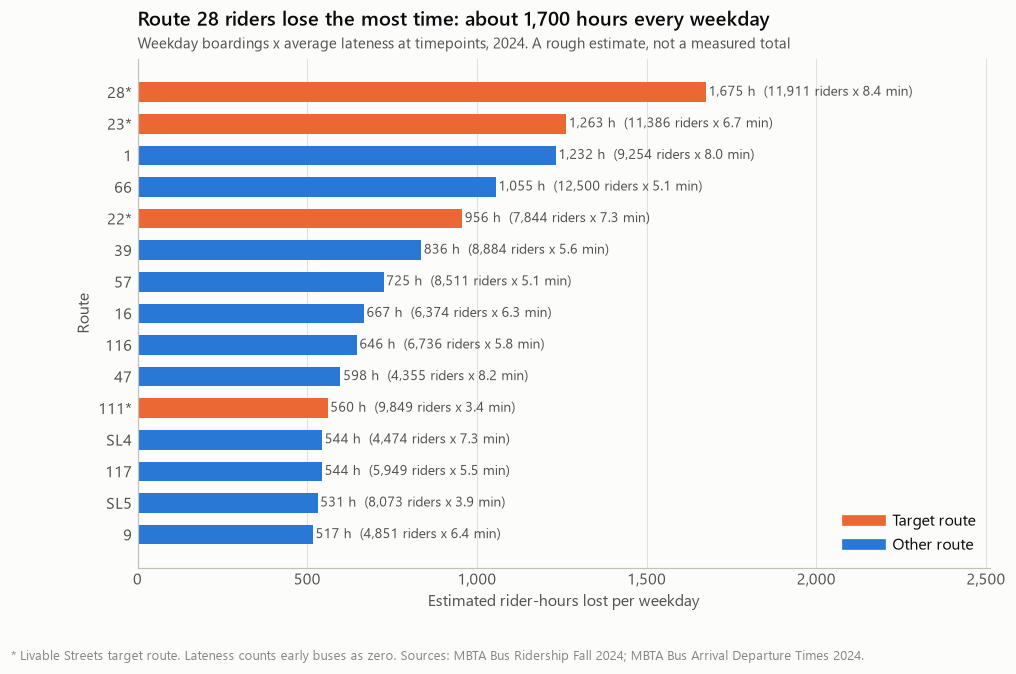

System total: 27,603 rider-hours per weekday, about 7.0 million per year at 255 weekdays.
Top 10 routes = 35%, top 15 = 45%, top 25 = 59% of lost hours across 147 routes. They carry 38% of boardings (top 15).
Target routes: 6,659 hours = 24% of the total, with 20% of boardings.


In [17]:
WEEKDAYS_PER_YEAR = 255
lost = []
for r in KEPT:
    b_ = R["Fall 2024"].get(r, 0)
    if b_:
        lost.append({"raw": r, "route": rlabel(r), "boardings": b_, "lateness_min": by_route[r]["lateness_min"], "hours_per_weekday": b_ * by_route[r]["lateness_min"] / 60})
lost.sort(key=lambda d: -d["hours_per_weekday"])
tot_h = sum(d["hours_per_weekday"] for d in lost)
cum = np.cumsum([d["hours_per_weekday"] for d in lost]) / tot_h
top15 = lost[:15][::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(15), [d["hours_per_weekday"] for d in top15], color=[ORANGE if d["raw"] in TARGET else BLUE for d in top15], height=.62)
for i, d in enumerate(top15):
    ax.text(d["hours_per_weekday"] + 8, i, f"{d['hours_per_weekday']:,.0f} h  ({d['boardings']:,.0f} riders x {d['lateness_min']:.1f} min)", va="center", fontsize=9, color=INK2)
ax.set_yticks(range(15), [d["route"] for d in top15]); ax.grid(axis="y", visible=False)
ax.set_xlim(0, top15[-1]["hours_per_weekday"] * 1.5); ax.set_xlabel("Estimated rider-hours lost per weekday"); ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}"); ax.set_ylabel("Route")
ax.legend(handles=[Line2D([], [], color=ORANGE, lw=7, label="Target route"), Line2D([], [], color=BLUE, lw=7, label="Other route")], loc="lower right")
title(ax, 'Route 28 riders lose the most time: about 1,700 hours every weekday', "Weekday boardings x average lateness at timepoints, 2024. A rough estimate, not a measured total")
source(fig, f"{TARGET_NOTE}. Lateness counts early buses as zero. Sources: MBTA Bus Ridership Fall 2024; MBTA Bus Arrival Departure Times 2024.")
save(fig, "fig10_hours_lost.png")
tl = sum(d["hours_per_weekday"] for d in lost if d["raw"] in TARGET)
print(f"System total: {tot_h:,.0f} rider-hours per weekday, about {tot_h * WEEKDAYS_PER_YEAR / 1e6:.1f} million per year at {WEEKDAYS_PER_YEAR} weekdays.")
print(f"Top 10 routes = {cum[9]:.0%}, top 15 = {cum[14]:.0%}, top 25 = {cum[24]:.0%} of lost hours across {len(lost)} routes. They carry {sum(d['boardings'] for d in lost[:15]) / sum(d['boardings'] for d in lost):.0%} of boardings (top 15).")
print(f"Target routes: {tl:,.0f} hours = {tl / tot_h:.0%} of the total, with {sum(d['boardings'] for d in lost if d['raw'] in TARGET) / sum(d['boardings'] for d in lost):.0%} of boardings.")
write_csv(OUT / "route_hours_lost.csv", lost, ["route", "boardings", "lateness_min", "hours_per_weekday"])

**Verdict: H7 is only weakly supported.** We estimate about 27,600 rider-hours lost per weekday, or about 7.0 million a year. Losses are spread out rather than highly concentrated: the top 15 of 147 routes account for 45% of lost hours and carry 38% of boardings. Target routes are 24% of lost hours with 20% of boardings. Routes 28, 23, and 22 stand out because both their ridership and their lateness are high, so this is where improvement could help the most riders.

**Defending this chart**
- *Why ranked bars?* The question is magnitude and rank by route. Bars on a zero baseline show this directly, and a pie chart could not compare 15 close values.
- *Why this measure?* Multiplying riders by lateness combines how many people are affected with how badly. This reverses the equal-weight view of Figure 5: Route 29 is the least reliable route but carries few riders, while Route 28 ranks above the median on the policy test (103rd of 150) and first here.
- *Could it mislead?* This is an estimate, and the chart says so. It assumes each boarding experiences the route's average timepoint lateness. It ignores transfers and missed connections, which would raise the total, and it does not separate waiting from time on board. Riders using real-time apps may also avoid some of the lateness, which would lower it. The per-route figures are useful for comparison, but the 7.0 million total should be read as an order of magnitude.

### Supporting table. Have the riders on each route changed since 2015-17?

In [18]:
wb = openpyxl.load_workbook(RAW / "CTPS_2015_17_survey_by_station_and_line.xlsx", read_only=True, data_only=True)
rows_ = list(wb["Line percentages"].iter_rows(values_only=True)); h = rows_[0]
imy, imn, ily, iln = [h.index(c) for c in ("Minority classification: Yes", "Minority classification: No", "Low-income classification: Yes", "Low-income classification: No")]
old = {}
for x in rows_[1:]:
    if x[0] == "Bus" and all(isinstance(x[i], (int, float)) for i in (imy, imn, ily, iln)) and (x[imy] + x[imn]) and (x[ily] + x[iln]):
        old[str(x[1]).strip()] = (100 * x[imy] / (x[imy] + x[imn]), 100 * x[ily] / (x[ily] + x[iln]))
new = {}
for g, d in groups.items():
    if re.fullmatch(r"\d+", g):
        new[g] = (yes_share(d["Title VI Minority"]) * 100, yes_share(d["Title VI Low-Income"]) * 100)
common = sorted(set(old) & set(new), key=int)
ch = [{"route": r, "minority 2015-17 %": old[r][0], "minority 2025 %": new[r][0], "low-income 2015-17 %": old[r][1], "low-income 2025 %": new[r][1]} for r in common]
write_csv(OUT / "route_demographics_over_time.csv", ch, list(ch[0]))
show(ch, fmt={c: "{:.0f}" for c in ch[0] if c != "route"})
print(f"{len(common)} single routes appear in both surveys. Median change in minority share: {np.median([new[r][0] - old[r][0] for r in common]):+.1f} pts; low-income share: {np.median([new[r][1] - old[r][1] for r in common]):+.1f} pts.")
print(f"Rank correlation between editions: minority {stats.spearmanr([old[r][0] for r in common], [new[r][0] for r in common])[0]:.2f}; low-income {stats.spearmanr([old[r][1] for r in common], [new[r][1] for r in common])[0]:.2f}.")
print("Check against the Livable Streets table: its low-income figures for routes 15, 23, and 111 (67.2, 59.0, 59.7) match this 2015-17 column, which confirms we read the right field.")

route,minority 2015-17 %,minority 2025 %,low-income 2015-17 %,low-income 2025 %
1,37,69,34,65
9,11,44,15,67
11,9,49,11,64
15,75,81,67,88
16,74,78,50,76
21,87,88,48,90
23,85,87,59,84
32,76,78,43,88
39,36,61,27,72
47,33,65,26,77


17 single routes appear in both surveys. Median change in minority share: +24.3 pts; low-income share: +39.1 pts.
Rank correlation between editions: minority 0.97; low-income 0.75.
Check against the Livable Streets table: its low-income figures for routes 15, 23, and 111 (67.2, 59.0, 59.7) match this 2015-17 column, which confirms we read the right field.


**This comparison does not support a claim of change over time.** The median route's minority share rises 24 points and its low-income share rises 39 points between surveys. These jumps are too large and uniform to accept as real change in riders. The two surveys used different methods, and low income in 2015-17 was a fixed threshold of under $43,500. The rank order is more stable, especially for minority share (rank correlation 0.97, against 0.75 for low income).

We therefore use this comparison only to say that the same routes tend to serve the highest shares of minority riders in both surveys. To compare levels, we would first need to reconcile the two surveys' methods and the 2025 low-income definition.

A table is used here instead of a chart, because a chart would give visual weight to differences that we do not trust.

## 6. Results by hypothesis

| # | Claim | Result | Key evidence |
|---|---|---|---|
| H1 | Ridership has not fully recovered, and recovery varies by route | **Supported** | 79% of Fall 2019 in Fall 2024; route median -20% |
| H2 | Trips take longer and are less predictable | **Partly supported** | Median run time +0.1 min; 10th-90th percentile spread of 16.4 min |
| H3 | Riders wait longer than promised | **Supported** | 8.6 vs 6.9 min on frequent service |
| H4 | Reliability differs between routes | **Supported** | 40% to 80% on time |
| H5 | Target routes perform worse | **Mixed** | On-time rate no different (p = 0.59); mean delay +1.38 min (p = 0.002) |
| H6 | Worse service falls on minority and low-income communities | **Partly supported** | On-time test: no link. Delay: modest link (tract rho = 0.25 with minority share) |
| H7 | Lost time is concentrated on a few routes | **Weakly supported** | Top 15 routes: 45% of hours, 38% of boardings |

### Answers to the project's base questions

| Question | Answer |
|---|---|
| Ridership per route, and pre- vs post-pandemic change | Figures 1 and 2; every route is in `ridership_route_season.csv`. All routes: 409,833 boardings in Fall 2019, 324,167 in Fall 2024. |
| End-to-end travel time per route | Figure 3; every route is in `travel_time_all_routes.csv`. |
| Average wait, on time vs delayed | Frequent service: 6.5 vs 11.5 min. Scheduled service, lateness past the timetable: 2.3 vs 8.6 min. |
| Average delay, all routes | 4.48 min (2024) |
| Average delay, target routes | 5.38 min (2024) |
| Which lines are late more often | Figure 5 and `route_reliability.csv`. Least reliable: 29, 245, 556, CT2, 19. |
| Who is most affected | Figures 7 to 9. Modest differences in lateness by neighborhood race and income; no difference on the on-time test. |
| Changes over time | Figures 1 and 6, plus the survey table above. |

## 7. Limitations and next steps

**Limitations**

- **Baseline:** January-February 2020 stands in for pre-pandemic service, because the 2018-2019 files are not publicly available.
- **Blank records:** a blank `actual` could be a dropped trip or a data gap. The policy would fail dropped trips, so our main on-time rates may be too high. Counting every blank as a failure lowers the 2024 rate from 66.3% to 61.4%.
- **Policy version:** we apply the Fall 2024 policy to 2020 data on purpose, so 2020 values are not the rates the MBTA would have reported then. We also have not reconciled our rates with the MBTA's published figures.
- **Weekdays only:** weekend service is not analyzed, and holidays falling on weekdays are still included.
- **Current stop locations:** 94% of timepoint crossings match a stop in today's GTFS feed. The remaining 6% are excluded from geographic analysis only.
- **Ecological inference:** route and tract averages cannot tell us about individual riders, and tract residents are not necessarily bus riders.
- **Causation:** these are associations. We have not controlled for traffic, route length, or street design.
- **Project document:** the Spring 2025 brief mentions "police overtime" and "complaints". These look like template leftovers from another project, so we did not treat them as requirements.

**Next steps, following our README timeline**

1. Get the route list for the 16 place-named survey groups, so that the Roxbury, Dorchester, and Mattapan riders can be included in Figure 8.
2. Ask Spark! whether the 2018 reliability and 2023 survey files can be shared directly.
3. Add time of day to the aggregates, and add 2021-2023 to fill the gap in Figure 6. Both are also needed as inputs for the delay model.
4. Fit a regression of delay on demographics that controls for route length, frequency, and ridership, to test whether the H6 link survives.
5. Build the planned model to predict delay by route, day, time, and season, with a time-based train and test split.

## 8. Outputs

| Location | Contents |
|---|---|
| `figures/` | All figures as 200 dpi PNG files |
| `data/processed/ridership_route_season.csv` | Weekday boardings by route and fall season |
| `data/processed/reliability_route_month.csv` | Crossings, on-time counts, delay, and lateness by route, month, timepoint type, and standard |
| `data/processed/route_reliability.csv` | One row per route: on-time rate, delay, boardings |
| `data/processed/route_delay_significance.csv` | Route delay tests across service days |
| `data/processed/travel_time_all_routes.csv` | Scheduled and actual run time with variation |
| `data/processed/wait_frequent.csv`, `wait_scheduled.csv` | Components of the wait calculations |
| `data/processed/route_equity_survey.csv`, `tract_reliability.csv` | Route-level and tract-level equity tables |
| `data/processed/route_hours_lost.csv` | Rider-hours lost by route |
| `data/processed/audit_*.csv` | Row-level cleaning audits |

To re-run everything from scratch, delete `data/processed/` and run all cells. The first run takes several minutes and downloads about 750 MB.